# Phase 2 — EDA diagnostique et qualité des données NBA

## Objectif

Diagnostiquer les cinq dimensions demandées par le guide, sans nettoyer les données :

1. **Complétude** ;
2. **Unicité** ;
3. **Cohérence** ;
4. **Exactitude** ;
5. **Fraîcheur**.

> Aucune suppression, imputation, standardisation ou jointure métier n'est réalisée ici. Les problèmes sont seulement mesurés, documentés et priorisés.

In [26]:
from __future__ import annotations
from pathlib import Path
from typing import Any
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT / "ML_NBA_Project" / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT / "ML_NBA_Project"

INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
RAW_API_DIR = PROJECT_ROOT / "data" / "raw" / "api"
REPORT_DIR = PROJECT_ROOT / "reports" / "phase2_diagnostic"
FIGURE_DIR = REPORT_DIR / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Projet :", PROJECT_ROOT.resolve())
print("Rapports :", REPORT_DIR.resolve())

Projet : C:\Users\axeln\OneDrive\LiveCampus\master\cours\machine learning\final\Model
Rapports : C:\Users\axeln\OneDrive\LiveCampus\master\cours\machine learning\final\Model\reports\phase2_diagnostic


## 1. Chargement des sources consolidées

In [27]:
SOURCE_FILES = {
    "player_bio": INTERIM_DIR / "player_bio_all_seasons.parquet",
    "player_stats_base": INTERIM_DIR / "player_stats_base_all_seasons.parquet",
    "player_stats_advanced": INTERIM_DIR / "player_stats_advanced_all_seasons.parquet",
    "team_stats_base": INTERIM_DIR / "team_stats_base_all_seasons.parquet",
    "team_stats_advanced": INTERIM_DIR / "team_stats_advanced_all_seasons.parquet",
    "rosters": INTERIM_DIR / "rosters_all_seasons.parquet",
}

sources = {}
for name, path in SOURCE_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Fichier manquant : {path}")
    sources[name] = pd.read_parquet(path)
    print(f"{name:25s} {sources[name].shape}")

kaggle_candidates = [
    PROJECT_ROOT / "data" / "raw" / "kaggle" / "all_seasons.csv",
    PROJECT_ROOT / "all_seasons.csv",
    PROJECT_ROOT / "all_seasons(2).csv",
]
kaggle_path = next((p for p in kaggle_candidates if p.exists()), None)
if kaggle_path:
    sources["kaggle_all_seasons"] = pd.read_csv(kaggle_path, low_memory=False)
    print(f"{'kaggle_all_seasons':25s} {sources['kaggle_all_seasons'].shape}")


def first_existing(frame, candidates):
    return next((c for c in candidates if c in frame.columns), None)

roster_team_col = first_existing(sources["rosters"], ["TEAM_ID", "TeamID", "TEAMID", "Team_ID"])
if roster_team_col is None:
    raise KeyError(f"Identifiant équipe introuvable dans rosters : {sources['rosters'].columns.tolist()}")

SOURCE_KEYS = {
    "player_bio": ["PLAYER_ID", "SEASON"],
    "player_stats_base": ["PLAYER_ID", "SEASON"],
    "player_stats_advanced": ["PLAYER_ID", "SEASON"],
    "team_stats_base": ["TEAM_ID", "SEASON"],
    "team_stats_advanced": ["TEAM_ID", "SEASON"],
    "rosters": ["PLAYER_ID", roster_team_col, "SEASON"],
}
if "kaggle_all_seasons" in sources:
    SOURCE_KEYS["kaggle_all_seasons"] = ["player_name", "season"]

SOURCE_SEASON = {
    name: first_existing(df, ["SEASON", "SEASON_YEAR", "season", "Season"])
    for name, df in sources.items()
}

print("Clé roster :", " + ".join(SOURCE_KEYS["rosters"]))

player_bio                (12846, 25)
player_stats_base         (12846, 69)
player_stats_advanced     (12846, 81)
team_stats_base           (802, 56)
team_stats_advanced       (802, 48)
rosters                   (11672, 18)
kaggle_all_seasons        (12844, 22)
Clé roster : PLAYER_ID + TeamID + SEASON


# Dimension 1 — Complétude

Les `NaN`, chaînes vides et valeurs textuelles représentant une absence sont comptées. La criticité suit les seuils du guide : jusqu'à 5 %, 5–30 %, puis plus de 30 %.

,source,colonne,type_pandas,lignes_total,null_nat_count,texte_absent_count,manquants_total,pourcentage_manquant,criticite
294,rosters,HOW_ACQUIRED,string,11672,11280,0,11280,96.6415,Haute
295,rosters,SUPPLEMENTAL_STATUS,float64,11672,5843,0,5843,50.0600,Haute
303,kaggle_all_seasons,college,str,12844,1854,5,1859,14.4737,Moyenne
8,player_bio,COLLEGE,string,12846,1821,0,1821,14.1756,Moyenne
12,player_bio,DRAFT_NUMBER,string,12846,104,0,104,0.8096,Faible
11,player_bio,DRAFT_ROUND,string,12846,95,0,95,0.7395,Faible
6,player_bio,PLAYER_HEIGHT_INCHES,float64,12846,71,0,71,0.5527,Faible
5,player_bio,PLAYER_HEIGHT,string,12846,71,0,71,0.5527,Faible
7,player_bio,PLAYER_WEIGHT,string,12846,6,65,71,0.5527,Faible
285,rosters,NUM,float64,11672,30,0,30,0.2570,Faible


,source,colonnes,colonnes_avec_manquants,colonnes_plus_5pct,colonnes_plus_30pct,cellules_manquantes
0,kaggle_all_seasons,22,1,1,0,1859
1,player_bio,25,6,1,0,2233
2,player_stats_advanced,81,0,0,0,0
3,player_stats_base,69,0,0,0,0
4,rosters,18,6,2,2,17167
5,team_stats_advanced,48,0,0,0,0
6,team_stats_base,56,0,0,0,0


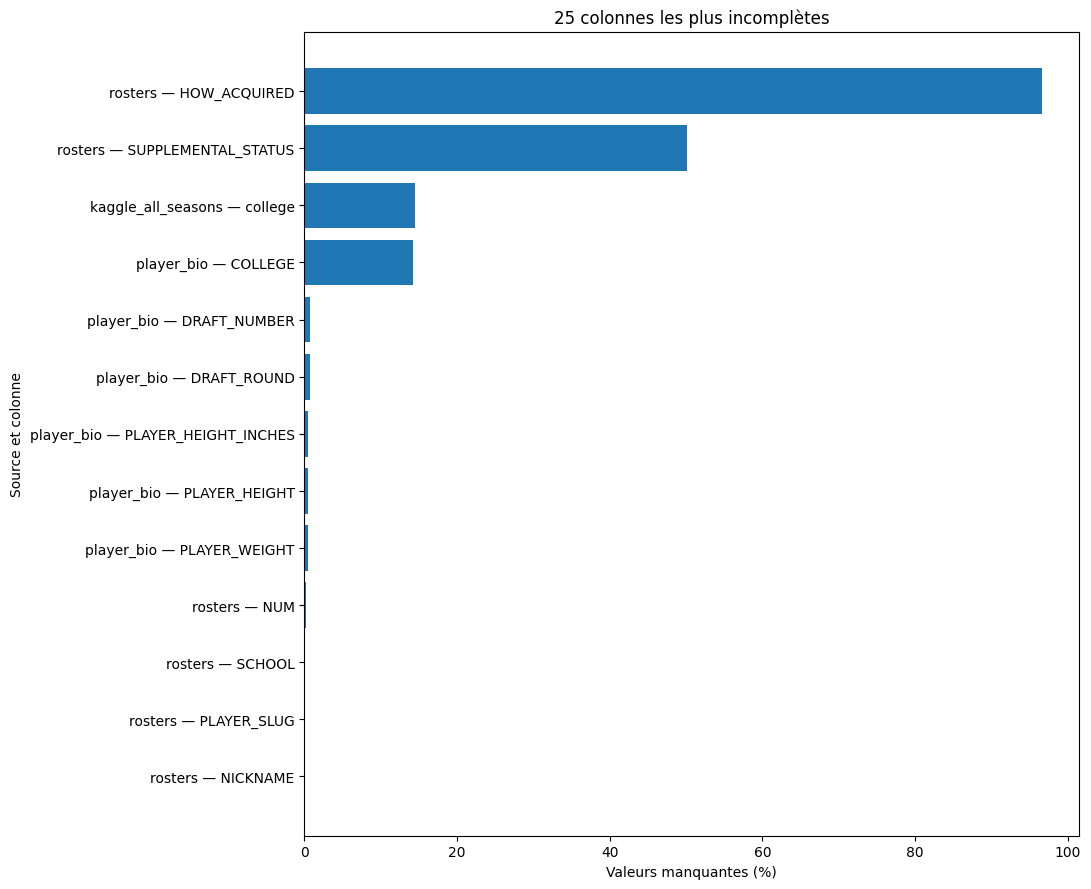

In [28]:
MISSING_TEXT = {"", "none", "null", "nan", "n/a", "na", "unknown", "not available"}

def text_missing_mask(series):
    if not (pd.api.types.is_object_dtype(series.dtype) or pd.api.types.is_string_dtype(series.dtype)):
        return pd.Series(False, index=series.index)
    return series.astype("string").str.strip().str.lower().isin(MISSING_TEXT).fillna(False)

def criticality(pct):
    if pct == 0: return "Aucune"
    if pct <= 5: return "Faible"
    if pct <= 30: return "Moyenne"
    return "Haute"

rows=[]
for source_name, df in sources.items():
    for col in df.columns:
        nulls = df[col].isna()
        textual = text_missing_mask(df[col])
        combined = nulls | textual
        n = int(combined.sum())
        pct = 100*n/len(df) if len(df) else np.nan
        rows.append({
            "source": source_name,
            "colonne": col,
            "type_pandas": str(df[col].dtype),
            "lignes_total": len(df),
            "null_nat_count": int(nulls.sum()),
            "texte_absent_count": int((textual & ~nulls).sum()),
            "manquants_total": n,
            "pourcentage_manquant": round(pct,4),
            "criticite": criticality(pct),
        })

completeness = pd.DataFrame(rows)
completeness.to_csv(REPORT_DIR / "01_completude_colonnes.csv", index=False, encoding="utf-8")
display(completeness.query("manquants_total > 0").sort_values("pourcentage_manquant", ascending=False).head(100))

summary_completeness = completeness.groupby("source", as_index=False).agg(
    colonnes=("colonne","count"),
    colonnes_avec_manquants=("manquants_total", lambda s: int((s>0).sum())),
    colonnes_plus_5pct=("pourcentage_manquant", lambda s: int((s>5).sum())),
    colonnes_plus_30pct=("pourcentage_manquant", lambda s: int((s>30).sum())),
    cellules_manquantes=("manquants_total","sum"),
)
display(summary_completeness)

top = completeness.query("manquants_total > 0").sort_values("pourcentage_manquant", ascending=False).head(25)
if not top.empty:
    labels = top["source"] + " — " + top["colonne"]
    plt.figure(figsize=(11,9))
    plt.barh(labels[::-1], top["pourcentage_manquant"][::-1])
    plt.xlabel("Valeurs manquantes (%)")
    plt.ylabel("Source et colonne")
    plt.title("25 colonnes les plus incomplètes")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "completude_top25.png", dpi=160, bbox_inches="tight")
    plt.show()

### Analyse de la complétude

Les principales tables statistiques sont très complètes. Les tables
`player_stats_base`, `player_stats_advanced`, `team_stats_base` et
`team_stats_advanced` ne présentent aucune valeur manquante.

Les problèmes de complétude sont principalement concentrés dans la table
`rosters`. La colonne `HOW_ACQUIRED` contient 96,64 % de valeurs manquantes
et `SUPPLEMENTAL_STATUS` 50,06 %. Ces deux colonnes sont donc considérées
comme critiques selon les seuils du guide.

La variable `COLLEGE` présente environ 14 % de valeurs manquantes aussi bien
dans la source Kaggle que dans la NBA API. Cette similarité entre les deux
sources suggère que ces absences ne proviennent pas simplement d'une erreur
d'extraction.

Les informations de draft, de taille et de poids présentent moins de 1 % de
valeurs manquantes et constituent donc des problèmes de faible criticité.

Aucune imputation statistique n'est réalisée durant cette phase. Les décisions
de suppression, de conservation ou de création de flags seront appliquées et
justifiées pendant la Phase 3.

In [29]:


columns_to_check = [
    "HOW_ACQUIRED",
    "SUPPLEMENTAL_STATUS",
]

missing_by_season_rows = []

rosters = sources["rosters"]

for column in columns_to_check:

    temp = (
        rosters
        .groupby("SEASON")[column]
        .agg(
            lignes="size",
            valeurs_manquantes=lambda s: s.isna().sum(),
            valeurs_presentes=lambda s: s.notna().sum(),
        )
        .reset_index()
    )

    temp["pct_manquant"] = (
        100
        * temp["valeurs_manquantes"]
        / temp["lignes"]
    )

    temp["colonne"] = column

    missing_by_season_rows.append(temp)


missing_by_season = pd.concat(
    missing_by_season_rows,
    ignore_index=True
)

display(missing_by_season)
missing_by_season_pivot = (
    missing_by_season
    .pivot(
        index="SEASON",
        columns="colonne",
        values="pct_manquant"
    )
)

display(
    missing_by_season_pivot.round(2)
)
bio = sources["player_bio"].copy()

college_missing_by_country = (
    bio
    .assign(
        COLLEGE_MISSING=bio["COLLEGE"].isna()
    )
    .groupby("COUNTRY")
    .agg(
        joueurs=("PLAYER_ID", "size"),
        college_manquant=("COLLEGE_MISSING", "sum"),
    )
    .reset_index()
)

college_missing_by_country["pct_manquant"] = (
    100
    * college_missing_by_country["college_manquant"]
    / college_missing_by_country["joueurs"]
)

display(
    college_missing_by_country
    .query("joueurs >= 10")
    .sort_values(
        "pct_manquant",
        ascending=False
    )
    .head(30)
)

,SEASON,lignes,valeurs_manquantes,valeurs_presentes,pct_manquant,colonne
0,1996-97,354,354,0,100.0,HOW_ACQUIRED
1,1997-98,351,351,0,100.0,HOW_ACQUIRED
2,1998-99,347,347,0,100.0,HOW_ACQUIRED
3,1999-00,344,344,0,100.0,HOW_ACQUIRED
4,2000-01,352,352,0,100.0,HOW_ACQUIRED
5,2001-02,367,367,0,100.0,HOW_ACQUIRED
6,2002-03,467,467,0,100.0,HOW_ACQUIRED
7,2003-04,416,416,0,100.0,HOW_ACQUIRED
8,2004-05,378,378,0,100.0,HOW_ACQUIRED
9,2005-06,413,413,0,100.0,HOW_ACQUIRED


colonne,HOW_ACQUIRED,SUPPLEMENTAL_STATUS
SEASON,,
1996-97,100.0,3.39
1997-98,100.0,3.42
1998-99,100.0,3.46
1999-00,100.0,3.49
2000-01,100.0,6.82
2001-02,100.0,0.0
2002-03,100.0,0.0
2003-04,100.0,3.37
2004-05,100.0,0.0


,COUNTRY,joueurs,college_manquant,pct_manquant
8,Bosnia and Herzegovina,20,20,100.000000
13,China,24,24,100.000000
18,Czech Republic,15,15,100.000000
19,DRC,14,14,100.000000
60,Slovenia,77,77,100.000000
40,Latvia,30,30,100.000000
67,Switzerland,23,23,100.000000
59,Serbia,120,119,99.166667
16,Croatia,83,82,98.795181
63,Spain,95,93,97.894737


## 2. Diagnostic de la complétude

### Rapport de complétude

| Source / Colonne | Valeurs manquantes | % manquant | Criticité | Action envisagée |
|---|---:|---:|---|---|
| rosters - HOW_ACQUIRED | 11 280 | 96,64 % | Haute | Suppression envisagée : colonne très incomplète et peu utile pour la cible |
| rosters - SUPPLEMENTAL_STATUS | 5 843 | 50,06 % | Haute | Suppression envisagée : disponibilité fortement dépendante de la saison |
| kaggle_all_seasons - college | 1 859 | 14,47 % | Moyenne | Conserver sans imputation statistique ; privilégier la colonne COLLEGE de la NBA API |
| player_bio - COLLEGE | 1 821 | 14,18 % | Moyenne | Conserver ; créer éventuellement un flag de valeur manquante |
| player_bio - DRAFT_NUMBER | 104 | 0,81 % | Faible | Vérifier les joueurs non draftés ; ne pas supprimer les lignes |
| player_bio - DRAFT_ROUND | 95 | 0,74 % | Faible | Même traitement que DRAFT_NUMBER |
| player_bio - PLAYER_HEIGHT_INCHES | 71 | 0,55 % | Faible | Vérifier si la valeur existe dans les rosters |
| player_bio - PLAYER_HEIGHT | 71 | 0,55 % | Faible | Vérifier si la valeur existe dans les rosters |
| player_bio - PLAYER_WEIGHT | 71 | 0,55 % | Faible | Vérifier si la valeur existe dans les rosters |
| rosters - NUM | 30 | 0,26 % | Faible | Suppression possible car numéro de maillot peu pertinent pour la prédiction |
| rosters - SCHOOL | 6 | 0,05 % | Faible | Conservation possible si la variable est retenue |
| rosters - PLAYER_SLUG | 4 | 0,03 % | Faible | Suppression envisagée : variable technique |
| rosters - NICKNAME | 4 | 0,03 % | Faible | Suppression envisagée : faible intérêt prédictif |

### Analyse du caractère aléatoire ou systématique des valeurs manquantes

Les valeurs manquantes ne sont pas réparties de manière aléatoire.

La colonne `HOW_ACQUIRED` présente une forte dépendance temporelle. Elle est
manquante à 100 % entre 1996-97 et 2008-09, puis reste presque entièrement
absente pendant plusieurs saisons. Sa complétude s'améliore progressivement
sur les saisons récentes, mais elle reste encore manquante à 75,59 % en
2022-23. Le manque est donc clairement systématique et lié à la disponibilité
historique de cette information dans l'API.

La colonne `SUPPLEMENTAL_STATUS` présente également un comportement
systématique. Elle est presque entièrement renseignée sur les anciennes
saisons, mais devient manquante à 100 % à partir de 2011-12 jusqu'à 2022-23.
Cela suggère un changement de structure ou de disponibilité de l'information
dans la source NBA API plutôt qu'un problème aléatoire ligne par ligne.

Les valeurs manquantes de `COLLEGE` sont elles aussi non aléatoires. Leur
fréquence dépend fortement du pays d'origine. Par exemple, les observations
concernant la Slovénie, la Chine, la Bosnie-Herzégovine ou la République
tchèque présentent 100 % de valeurs manquantes, tandis que la France atteint
environ 84 %. Cette structure est cohérente avec le fait qu'un grand nombre de
joueurs internationaux n'ont pas suivi un parcours universitaire américain.
L'absence de `COLLEGE` peut donc être considérée comme partiellement
informative plutôt que comme une simple erreur de saisie.

Les autres valeurs manquantes concernent moins de 1 % des observations. Elles
seront analysées individuellement pendant la phase de nettoyage et pourront
éventuellement être récupérées depuis une autre source.

Aucune imputation par moyenne, médiane ou mode n'est réalisée pendant cette
phase afin d'éviter tout risque de fuite de données.

In [30]:
college_missing_by_country = (
    bio
    .assign(COLLEGE_MISSING=bio["COLLEGE"].isna())
    .groupby("COUNTRY")
    .agg(
        lignes=("PLAYER_ID", "size"),
        joueurs_uniques=("PLAYER_ID", "nunique"),
        college_manquant=("COLLEGE_MISSING", "sum"),
    )
    .reset_index()
)

college_missing_by_country["pct_manquant"] = (
    100
    * college_missing_by_country["college_manquant"]
    / college_missing_by_country["lignes"]
)

display(
    college_missing_by_country
    .query("lignes >= 10")
    .sort_values("pct_manquant", ascending=False)
    .head(30)
)

,COUNTRY,lignes,joueurs_uniques,college_manquant,pct_manquant
8,Bosnia and Herzegovina,20,5,20,100.000000
13,China,24,6,24,100.000000
18,Czech Republic,15,4,15,100.000000
19,DRC,14,2,14,100.000000
60,Slovenia,77,11,77,100.000000
40,Latvia,30,6,30,100.000000
67,Switzerland,23,2,23,100.000000
59,Serbia,120,28,119,99.166667
16,Croatia,83,20,82,98.795181
63,Spain,95,15,93,97.894737


### Checklist complétude

- [x] Calculer le nombre de valeurs manquantes par colonne
- [x] Calculer le pourcentage de valeurs manquantes
- [x] Identifier les colonnes avec > 5 % de manquants
- [x] Identifier les colonnes avec > 30 % de manquants
- [x] Vérifier si les manquants sont aléatoires ou systématiques

# Dimension 2 — Unicité

Les doublons exacts sont calculés en ignorant `SOURCE_FILE`. Les doublons sur les clés candidates sont exportés pour analyse. Un doublon de roster peut correspondre à un transfert et ne doit pas être supprimé automatiquement.

In [31]:
uniqueness_rows=[]
detail_frames=[]
for source_name, df in sources.items():
    keys = SOURCE_KEYS[source_name]
    diagnostic_df = df.drop(columns=["SOURCE_FILE"], errors="ignore")
    exact_mask = diagnostic_df.duplicated(keep=False)
    key_missing = int(df[keys].isna().any(axis=1).sum())
    key_dup_mask = df.duplicated(subset=keys, keep=False)
    key_dup_rows = int(key_dup_mask.sum())
    key_dup_groups = int(df.loc[key_dup_mask, keys].drop_duplicates().shape[0])

    uniqueness_rows.append({
        "source": source_name,
        "lignes": len(df),
        "cle_candidate": " + ".join(keys),
        "lignes_cle_manquante": key_missing,
        "lignes_doublons_cle": key_dup_rows,
        "groupes_doublons_cle": key_dup_groups,
        "lignes_doublons_exacts": int(exact_mask.sum()),
        "pourcentage_doublons_cle": round(100*key_dup_rows/len(df),4) if len(df) else np.nan,
        "statut": "OK" if key_missing == 0 and key_dup_rows == 0 else "À analyser",
    })

    if key_dup_rows:
        part = df.loc[key_dup_mask].copy()
        part.insert(0,"SOURCE_DIAGNOSTIC",source_name)
        part.insert(1,"TYPE_PROBLEME","Doublon sur clé candidate")
        detail_frames.append(part)
    if exact_mask.any():
        part = df.loc[exact_mask].copy()
        part.insert(0,"SOURCE_DIAGNOSTIC",source_name)
        part.insert(1,"TYPE_PROBLEME","Doublon exact")
        detail_frames.append(part)

uniqueness = pd.DataFrame(uniqueness_rows)
uniqueness.to_csv(REPORT_DIR / "02_unicite_sources.csv", index=False, encoding="utf-8")
duplicate_details = pd.concat(detail_frames, ignore_index=True, sort=False) if detail_frames else pd.DataFrame()
duplicate_details.to_csv(REPORT_DIR / "03_doublons_cles_details.csv", index=False, encoding="utf-8")
display(uniqueness)

,source,lignes,cle_candidate,lignes_cle_manquante,lignes_doublons_cle,groupes_doublons_cle,lignes_doublons_exacts,pourcentage_doublons_cle,statut
0,player_bio,12846,PLAYER_ID + SEASON,0,0,0,0,0.0000,OK
1,player_stats_base,12846,PLAYER_ID + SEASON,0,0,0,0,0.0000,OK
2,player_stats_advanced,12846,PLAYER_ID + SEASON,0,0,0,0,0.0000,OK
3,team_stats_base,802,TEAM_ID + SEASON,0,0,0,0,0.0000,OK
4,team_stats_advanced,802,TEAM_ID + SEASON,0,0,0,0,0.0000,OK
5,rosters,11672,PLAYER_ID + TeamID + SEASON,0,0,0,0,0.0000,OK
6,kaggle_all_seasons,12844,player_name + season,0,8,4,0,0.0623,À analyser


In [ ]:

# QUASI-DOUBLONS MÉTIER : JOUEURS DANS PLUSIEURS ÉQUIPES DURANT UNE MÊME SAISON

rosters_df = sources["rosters"].copy()

roster_multi_team = (
    rosters_df
    .groupby(["PLAYER_ID", "SEASON"])
    .agg(
        nombre_equipes=("TeamID", "nunique"),
        equipes=("TeamID", lambda x: " | ".join(
            map(str, sorted(x.dropna().unique()))
        ))
    )
    .reset_index()
)

roster_multi_team = roster_multi_team[
    roster_multi_team["nombre_equipes"] > 1
].copy()

print(
    "Nombre de couples joueur-saison présents dans plusieurs équipes :",
    len(roster_multi_team)
)

display(
    roster_multi_team
    .sort_values("nombre_equipes", ascending=False)
    .head(50)
)

roster_multi_team_details = (
    rosters_df
    .merge(
        roster_multi_team[
            ["PLAYER_ID", "SEASON"]
        ],
        on=["PLAYER_ID", "SEASON"],
        how="inner"
    )
    .sort_values(
        ["SEASON", "PLAYER_ID", "TeamID"]
    )
)

display(roster_multi_team_details.head(100))

roster_multi_team_details.to_csv(
    REPORT_DIR / "03b_quasi_doublons_transferts.csv",
    index=False,
    encoding="utf-8"
)




In [32]:
# QUASI-DOUBLONS KAGGLE : NOM NORMALISÉ + SAISON


kaggle_df = sources["kaggle_all_seasons"].copy()

kaggle_df["player_name_normalized"] = (
    kaggle_df["player_name"]
    .astype("string")
    .str.normalize("NFKD")
    .str.encode("ascii", errors="ignore")
    .str.decode("ascii")
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
)

kaggle_quasi_mask = kaggle_df.duplicated(
    subset=[
        "player_name_normalized",
        "season"
    ],
    keep=False
)

kaggle_quasi_duplicates = (
    kaggle_df.loc[kaggle_quasi_mask]
    .sort_values([
        "season",
        "player_name_normalized"
    ])
)

print(
    "Lignes potentiellement quasi-dupliquées dans Kaggle :",
    len(kaggle_quasi_duplicates)
)

display(kaggle_quasi_duplicates.head(100))

unicite_template = uniqueness[
    [
        "source",
        "lignes",
        "lignes_doublons_exacts",
        "lignes_doublons_cle",
        "pourcentage_doublons_cle"
    ]
].copy()

unicite_template.columns = [
    "DataFrame",
    "Lignes totales",
    "Doublons exacts",
    "Doublons ID",
    "% doublons"
]

display(unicite_template)

Nombre de couples joueur-saison présents dans plusieurs équipes : 1


,PLAYER_ID,SEASON,nombre_equipes,equipes
9348,203915,2015-16,2,1610612741 | 1610612765


,TeamID,SEASON,LeagueID,PLAYER,NICKNAME,PLAYER_SLUG,NUM,POSITION,HEIGHT,WEIGHT,BIRTH_DATE,AGE,EXP,SCHOOL,PLAYER_ID,HOW_ACQUIRED,SUPPLEMENTAL_STATUS,SOURCE_FILE
0,1610612741,2015-16,0,Spencer Dinwiddie,Spencer,spencer-dinwiddie,8.0,G,6-6,200,"APR 06, 1993",23.0,1,Colorado,203915,<NA>,NaN,roster_1610612741_2015_16.csv
1,1610612765,2015-16,0,Spencer Dinwiddie,Spencer,spencer-dinwiddie,8.0,G,6-6,200,"APR 06, 1993",23.0,1,Colorado,203915,<NA>,NaN,roster_1610612765_2015_16.csv


Lignes potentiellement quasi-dupliquées dans Kaggle : 8


,Unnamed: 0,player_name,team_abbreviation,age,player_height,player_weight,college,country,draft_year,draft_round,draft_number,gp,pts,reb,ast,net_rating,oreb_pct,dreb_pct,usg_pct,ts_pct,ast_pct,season,player_name_normalized
5163,5163,Marcus Williams,LAC,21.0,200.66,93.893544,Arizona,USA,2007,2,33,11,0.9,1.1,0.3,-1.1,0.080,0.242,0.232,0.250,0.143,2007-08,marcus williams
5164,5164,Marcus Williams,NJN,22.0,190.50,92.986360,Connecticut,USA,2006,1,22,53,5.9,1.9,2.6,-11.2,0.019,0.124,0.212,0.499,0.285,2007-08,marcus williams
5635,5635,Marcus Williams,GSW,23.0,190.50,95.254320,Connecticut,USA,2006,1,22,9,1.3,0.4,1.4,-5.5,0.000,0.073,0.181,0.305,0.342,2008-09,marcus williams
5643,5643,Marcus Williams,SAS,22.0,200.66,93.893544,Arizona,USA,2007,2,33,2,2.0,0.0,0.0,-52.3,0.000,0.000,0.240,1.000,0.000,2008-09,marcus williams
7291,7291,Chris Johnson,MIN,27.0,210.82,95.254320,Louisiana State,USA,Undrafted,Undrafted,Undrafted,30,3.9,2.0,0.3,-4.1,0.085,0.153,0.166,0.650,0.042,2012-13,chris johnson
7292,7292,Chris Johnson,MEM,23.0,198.12,91.171992,Dayton,USA,Undrafted,Undrafted,Undrafted,8,3.6,1.4,0.3,18.1,0.051,0.073,0.124,0.560,0.025,2012-13,chris johnson
7962,7962,Tony Mitchell,MIL,24.0,198.12,97.975872,Alabama,USA,Undrafted,Undrafted,Undrafted,3,2.0,0.3,0.3,3.1,0.167,0.000,0.242,0.600,0.200,2013-14,tony mitchell
7963,7963,Tony Mitchell,DET,22.0,203.20,106.594120,North Texas,USA,2013,2,37,21,1.0,1.2,0.1,2.6,0.174,0.177,0.132,0.540,0.040,2013-14,tony mitchell


,DataFrame,Lignes totales,Doublons exacts,Doublons ID,% doublons
0,player_bio,12846,0,0,0.0000
1,player_stats_base,12846,0,0,0.0000
2,player_stats_advanced,12846,0,0,0.0000
3,team_stats_base,802,0,0,0.0000
4,team_stats_advanced,802,0,0,0.0000
5,rosters,11672,0,0,0.0000
6,kaggle_all_seasons,12844,0,8,0.0623


## 3. Diagnostic de l'Unicité

### Rapport d'unicité

| DataFrame | Lignes totales | Doublons exacts | Doublons sur la clé candidate | % doublons |
|---|---:|---:|---:|---:|
| player_bio | 12 846 | 0 | 0 | 0,0000 % |
| player_stats_base | 12 846 | 0 | 0 | 0,0000 % |
| player_stats_advanced | 12 846 | 0 | 0 | 0,0000 % |
| team_stats_base | 802 | 0 | 0 | 0,0000 % |
| team_stats_advanced | 802 | 0 | 0 | 0,0000 % |
| rosters | 11 672 | 0 | 0 | 0,0000 % |
| kaggle_all_seasons | 12 844 | 0 | 8 | 0,0623 % |

### Analyse de l'unicité

Les sources issues de la NBA API présentent une très bonne unicité.

Aucun doublon exact n'a été détecté dans les tables `player_bio`,
`player_stats_base`, `player_stats_advanced`, `team_stats_base`,
`team_stats_advanced` et `rosters`.

Les clés candidates suivantes sont uniques dans les données :

- `PLAYER_ID + SEASON` pour les statistiques joueurs ;
- `TEAM_ID + SEASON` pour les statistiques équipes ;
- `PLAYER_ID + TeamID + SEASON` pour les rosters.

Ces clés ne présentent aucune valeur manquante et aucun doublon.

Le dataset Kaggle présente 8 lignes dupliquées selon la clé candidate
`player_name + season`, soit seulement 0,0623 % des lignes. Cependant,
l'analyse détaillée montre qu'il ne s'agit pas de véritables doublons :
plusieurs joueurs différents peuvent porter exactement le même nom pendant
une même saison.



### Analyse des quasi-doublons du dataset Kaggle

Les 8 lignes détectées avec la clé `player_name + season` correspondent à
4 groupes de noms identiques.

Par exemple, deux joueurs nommés `Marcus Williams` apparaissent en 2007-08.
Ils peuvent être distingués grâce à plusieurs attributs :

- université différente : Arizona / Connecticut ;
- draft différente : 2007 choix 33 / 2006 choix 22 ;
- taille différente ;
- âge différent ;
- équipe différente.

Le même phénomène est observé pour `Chris Johnson` en 2012-13 et
`Tony Mitchell` en 2013-14.

Ces cas sont donc des homonymes et non des doublons à supprimer.

Cela montre que `player_name + season` n'est pas une véritable clé primaire
pour le dataset Kaggle. L'identifiant `PLAYER_ID` fourni par la NBA API sera
privilégié dans le dataset final.



### Quasi-doublons métier dans les rosters

Un seul couple `PLAYER_ID + SEASON` apparaît dans plusieurs équipes :
Spencer Dinwiddie (`PLAYER_ID = 203915`) durant la saison 2015-16.

Deux lignes existent car le joueur est associé à deux équipes différentes.
Comme `TeamID` diffère, ces lignes ne constituent pas un doublon selon la
clé du roster `PLAYER_ID + TeamID + SEASON`.

Il s'agit d'une situation métier légitime liée à un changement d'effectif
au cours de la saison.

Ce cas devra néanmoins être pris en compte lors de la construction du
dataset final, dont le grain prévu est une ligne par joueur et par saison.
Aucune ligne n'est supprimée à ce stade.



### Réponses aux questions sur l'unicité

**Les doublons sont-ils des erreurs d'export ou des vraies occurrences ?**

Aucun doublon exact n'a été identifié dans les sources NBA API.
Les 8 lignes signalées dans Kaggle sont de vraies occurrences correspondant
à des joueurs homonymes et ne doivent donc pas être supprimées.

**Y a-t-il une raison métier pour avoir des lignes similaires ?**

Oui. Plusieurs joueurs NBA peuvent avoir le même nom. De plus, un joueur
peut être associé à plusieurs équipes au cours d'une même saison, notamment
en cas de transfert ou de changement d'effectif.

**Quelle est la vraie clé primaire des données ?**

Les clés retenues sont :

- joueurs : `PLAYER_ID + SEASON` ;
- équipes : `TEAM_ID + SEASON` ;
- rosters bruts : `PLAYER_ID + TeamID + SEASON`.

Dans le dataset Kaggle, `player_name + season` ne constitue qu'une clé
candidate imparfaite car plusieurs joueurs différents peuvent partager le
même nom.

Le dataset final de machine learning aura pour grain une observation par
joueur et par saison et utilisera donc `PLAYER_ID + SEASON` comme clé.



### Checklist unicité

- [x] Compter les lignes en double exactes
- [x] Identifier les doublons sur la clé primaire / candidate
- [x] Vérifier les quasi-doublons
- [x] Calculer le pourcentage de doublons

# Dimension 4 — Cohérence


In [ ]:


import re
import numpy as np
import pandas as pd


MAX_DISPLAY_ROWS = 20


def display_compact(df, title=None, n=MAX_DISPLAY_ROWS):
    if title:
        print(f"\n{title}")

    if df is None or df.empty:
        print("Aucune anomalie détectée.")
        return

    print(f"Affichage : {min(len(df), n)} / {len(df)} lignes")
    display(df.head(n))


def normalize_category(series):
    """
    Normalisation uniquement pour le diagnostic :
    casse, accents, ponctuation et espaces.
    Aucune modification des données sources.
    """
    return (
        series
        .astype("string")
        .str.strip()
        .str.lower()
        .str.normalize("NFKD")
        .str.encode("ascii", errors="ignore")
        .str.decode("ascii")
        .str.replace(r"[^a-z0-9]+", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )





In [ ]:
# 4.1 COHÉRENCE DU FORMAT DES SAISONS


season_rows = []

for source_name, df in sources.items():

    season_col = next(
        (
            c for c in
            ["SEASON", "SEASON_YEAR", "season", "Season"]
            if c in df.columns
        ),
        None
    )

    if season_col is None:
        continue

    s = (
        df[season_col]
        .dropna()
        .astype("string")
        .str.strip()
    )

    invalid = ~s.str.match(
        r"^\d{4}-\d{2}$",
        na=False
    )

    season_rows.append({
        "source": source_name,
        "colonne_saison": season_col,
        "valeurs_distinctes": s.nunique(),
        "formats_invalides": int(invalid.sum()),
        "exemples_invalides": " | ".join(
            s[invalid]
            .drop_duplicates()
            .head(10)
            .tolist()
        )
    })


season_report = pd.DataFrame(season_rows)

season_report.to_csv(
    REPORT_DIR / "04a_coherence_saisons.csv",
    index=False,
    encoding="utf-8"
)

display_compact(
    season_report,
    "Cohérence des saisons"
)





In [ ]:
# 4.2 VARIABLES CATÉGORIELLES
# - valeurs uniques
# - espaces
# - casse
# - variations après normalisation
# - colonnes texte contenant principalement des nombres


category_summary_rows = []
category_values_rows = []
category_variants_rows = []


for source_name, df in sources.items():

    categorical_cols = df.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for col in categorical_cols:

        s = (
            df[col]
            .dropna()
            .astype("string")
        )

        if s.empty:
            continue

        stripped = s.str.strip()

        # ---------- valeurs uniques ----------
        counts = stripped.value_counts()

        for value, count in counts.items():
            category_values_rows.append({
                "source": source_name,
                "colonne": col,
                "valeur": value,
                "nombre": int(count)
            })

        # ---------- espaces externes ----------
        external_spaces = int(
            (s != stripped).sum()
        )

        # ---------- variations de casse ----------
        case_temp = pd.DataFrame({
            "valeur": stripped.drop_duplicates()
        })

        case_temp["minuscule"] = (
            case_temp["valeur"]
            .str.lower()
        )

        case_groups = (
            case_temp
            .groupby("minuscule")["valeur"]
            .nunique()
        )

        case_variants = int(
            (case_groups > 1).sum()
        )

        # ---------- accents / ponctuation / orthographe simple ----------
        variant_temp = pd.DataFrame({
            "valeur": stripped.drop_duplicates()
        })

        variant_temp["normalisee"] = normalize_category(
            variant_temp["valeur"]
        )

        variant_groups = (
            variant_temp
            .groupby("normalisee")["valeur"]
            .agg(list)
        )

        normalized_variant_count = 0

        for normalized, values in variant_groups.items():

            unique_values = sorted(
                set(map(str, values))
            )

            if len(unique_values) > 1:

                normalized_variant_count += 1

                category_variants_rows.append({
                    "source": source_name,
                    "colonne": col,
                    "normalisee": normalized,
                    "variantes": " | ".join(
                        unique_values
                    )
                })

        # ---------- texte convertible en numérique ----------
        numeric = pd.to_numeric(
            stripped,
            errors="coerce"
        )

        numeric_count = int(
            numeric.notna().sum()
        )

        numeric_pct = (
            100 * numeric_count / len(stripped)
            if len(stripped)
            else np.nan
        )

        category_summary_rows.append({
            "source": source_name,
            "colonne": col,
            "valeurs_non_manquantes": len(s),
            "valeurs_uniques": stripped.nunique(),
            "lignes_avec_espaces_externes": external_spaces,
            "variantes_potentielles_de_casse": case_variants,
            "groupes_variantes_normalisees": normalized_variant_count,
            "valeurs_convertibles_en_numerique": numeric_count,
            "pourcentage_convertible_en_numerique": round(
                numeric_pct,
                4
            )
        })


category_consistency = pd.DataFrame(
    category_summary_rows
)

category_values = pd.DataFrame(
    category_values_rows
)

category_variants = pd.DataFrame(
    category_variants_rows
)


category_consistency.to_csv(
    REPORT_DIR / "04b_coherence_categories_resume.csv",
    index=False,
    encoding="utf-8"
)

# Toutes les valeurs uniques sont enregistrées ici,
# mais pas affichées intégralement dans le notebook.
category_values.to_csv(
    REPORT_DIR / "04c_coherence_categories_valeurs_uniques.csv",
    index=False,
    encoding="utf-8"
)

category_variants.to_csv(
    REPORT_DIR / "04d_coherence_variantes.csv",
    index=False,
    encoding="utf-8"
)


category_issues = category_consistency[
    (
        category_consistency["lignes_avec_espaces_externes"] > 0
    )
    |
    (
        category_consistency[
            "variantes_potentielles_de_casse"
        ] > 0
    )
    |
    (
        category_consistency[
            "groupes_variantes_normalisees"
        ] > 0
    )
    |
    (
        category_consistency[
            "pourcentage_convertible_en_numerique"
        ] > 50
    )
].sort_values(
    [
        "lignes_avec_espaces_externes",
        "groupes_variantes_normalisees"
    ],
    ascending=False
)


display_compact(
    category_issues,
    "Problèmes potentiels de cohérence catégorielle"
)

display_compact(
    category_variants,
    "Variantes de libellés détectées"
)





In [ ]:
# 4.3 APERÇU DES VARIABLES CATÉGORIELLES MÉTIER


categorical_columns_to_check = {
    "player_bio": [
        "COUNTRY",
        "COLLEGE",
        "TEAM_ABBREVIATION",
    ],
    "rosters": [
        "POSITION",
        "SCHOOL",
    ],
    "kaggle_all_seasons": [
        "country",
        "college",
        "team_abbreviation",
    ],
}


for source_name, columns in categorical_columns_to_check.items():

    df = sources[source_name]

    print("\n" + "=" * 70)
    print(source_name)
    print("=" * 70)

    for col in columns:

        if col not in df.columns:
            continue

        values = (
            df[col]
            .dropna()
            .astype("string")
            .str.strip()
            .value_counts()
            .rename("nombre")
            .reset_index()
        )

        values.columns = [
            "valeur",
            "nombre"
        ]

        print(
            f"\n{col} : "
            f"{len(values)} valeurs distinctes"
        )

        display_compact(
            values,
            n=20
        )





In [ ]:
# 4.4 COHÉRENCE INTER-SOURCES DES CATÉGORIES


def compare_categories(
    source_a,
    col_a,
    source_b,
    col_b,
    max_rows=20
):

    a = (
        sources[source_a][col_a]
        .dropna()
        .astype("string")
        .str.strip()
        .drop_duplicates()
    )

    b = (
        sources[source_b][col_b]
        .dropna()
        .astype("string")
        .str.strip()
        .drop_duplicates()
    )

    a_norm = pd.DataFrame({
        "valeur_a": a
    })

    a_norm["normalisee"] = normalize_category(
        a_norm["valeur_a"]
    )

    b_norm = pd.DataFrame({
        "valeur_b": b
    })

    b_norm["normalisee"] = normalize_category(
        b_norm["valeur_b"]
    )

    normalized_a = set(
        a_norm["normalisee"]
    )

    normalized_b = set(
        b_norm["normalisee"]
    )

    matched = (
        normalized_a
        & normalized_b
    )

    merged = a_norm.merge(
        b_norm,
        on="normalisee",
        how="outer",
        indicator=True
    )

    only_a = merged[
        merged["_merge"] == "left_only"
    ][
        ["valeur_a", "normalisee"]
    ]

    only_b = merged[
        merged["_merge"] == "right_only"
    ][
        ["valeur_b", "normalisee"]
    ]

    summary = {
        "comparaison":
            f"{source_a}.{col_a} VS "
            f"{source_b}.{col_b}",

        "valeurs_distinctes_a":
            len(a),

        "valeurs_distinctes_b":
            len(b),

        "correspondances_normalisees":
            len(matched),

        "uniquement_a":
            len(only_a),

        "uniquement_b":
            len(only_b)
    }

    print(
        "\n",
        summary["comparaison"]
    )

    print(
        "Valeurs distinctes :",
        len(a),
        "vs",
        len(b)
    )

    print(
        "Correspondances normalisées :",
        len(matched)
    )

    print(
        f"Uniquement {source_a} :",
        len(only_a)
    )

    display_compact(
        only_a,
        n=max_rows
    )

    print(
        f"Uniquement {source_b} :",
        len(only_b)
    )

    display_compact(
        only_b,
        n=max_rows
    )

    return summary, merged


comparison_specs = [
    (
        "player_bio",
        "COUNTRY",
        "kaggle_all_seasons",
        "country"
    ),
    (
        "player_bio",
        "COLLEGE",
        "kaggle_all_seasons",
        "college"
    ),
    (
        "player_bio",
        "COLLEGE",
        "rosters",
        "SCHOOL"
    ),
    (
        "player_bio",
        "TEAM_ABBREVIATION",
        "kaggle_all_seasons",
        "team_abbreviation"
    ),
]


comparison_summary_rows = []
comparison_detail_frames = []


for (
    source_a,
    col_a,
    source_b,
    col_b
) in comparison_specs:

    if (
        source_a not in sources
        or source_b not in sources
        or col_a not in sources[source_a].columns
        or col_b not in sources[source_b].columns
    ):
        continue

    summary, details = compare_categories(
        source_a,
        col_a,
        source_b,
        col_b
    )

    comparison_summary_rows.append(
        summary
    )

    details.insert(
        0,
        "comparaison",
        summary["comparaison"]
    )

    comparison_detail_frames.append(
        details
    )


comparison_summary = pd.DataFrame(
    comparison_summary_rows
)

comparison_details = (
    pd.concat(
        comparison_detail_frames,
        ignore_index=True
    )
    if comparison_detail_frames
    else pd.DataFrame()
)


comparison_summary.to_csv(
    REPORT_DIR / "04e_coherence_inter_sources_resume.csv",
    index=False,
    encoding="utf-8"
)

comparison_details.to_csv(
    REPORT_DIR / "04f_coherence_inter_sources_details.csv",
    index=False,
    encoding="utf-8"
)

display_compact(
    comparison_summary,
    "Résumé des comparaisons catégorielles inter-sources"
)





In [ ]:
# 4.5 CANDIDATS D'ABRÉVIATIONS REPRÉSENTANT
#     POTENTIELLEMENT LA MÊME CHOSE


STOPWORDS_ACRONYM = {
    "of",
    "the",
    "and",
    "de",
    "la",
    "le",
    "du",
    "des"
}


def build_acronym(value):

    normalized = normalize_category(
        pd.Series([value])
    ).iloc[0]

    tokens = [
        token
        for token in normalized.split()
        if token not in STOPWORDS_ACRONYM
    ]

    if len(tokens) < 2:
        return None

    return "".join(
        token[0]
        for token in tokens
    )


alias_rows = []


for source_name, columns in categorical_columns_to_check.items():

    df = sources[source_name]

    for col in columns:

        if col not in df.columns:
            continue

        values = (
            df[col]
            .dropna()
            .astype("string")
            .str.strip()
            .drop_duplicates()
            .tolist()
        )

        long_by_acronym = {}

        for value in values:

            acronym = build_acronym(
                value
            )

            if acronym:

                long_by_acronym.setdefault(
                    acronym.lower(),
                    []
                ).append(value)

        for value in values:

            value_text = str(value).strip()

            # Abréviation courte en majuscules :
            # ex. DRC, USA, UCLA...
            if not re.fullmatch(
                r"[A-Z]{2,6}",
                value_text
            ):
                continue

            key = value_text.lower()

            candidates = long_by_acronym.get(
                key,
                []
            )

            for candidate in candidates:

                if candidate == value:
                    continue

                alias_rows.append({
                    "source": source_name,
                    "colonne": col,
                    "abreviation": value,
                    "libelle_long_candidat": candidate,
                    "statut":
                        "À vérifier manuellement"
                })


semantic_alias_candidates = (
    pd.DataFrame(alias_rows)
    .drop_duplicates()
)


semantic_alias_candidates.to_csv(
    REPORT_DIR / "04g_coherence_alias_semantiques.csv",
    index=False,
    encoding="utf-8"
)

display_compact(
    semantic_alias_candidates,
    "Abréviations pouvant représenter la même chose"
)





In [ ]:
# 4.6 COHÉRENCE DES UNITÉS


unit_specs = [
    {
        "source": "kaggle_all_seasons",
        "colonne": "player_height",
        "unite_source": "cm",
        "unite_cible": "cm",
        "action_phase3": "Aucune conversion"
    },
    {
        "source": "kaggle_all_seasons",
        "colonne": "player_weight",
        "unite_source": "kg",
        "unite_cible": "kg",
        "action_phase3": "Aucune conversion"
    },
    {
        "source": "player_bio",
        "colonne": "PLAYER_HEIGHT_INCHES",
        "unite_source": "pouces",
        "unite_cible": "cm",
        "action_phase3": "Multiplier par 2.54"
    },
    {
        "source": "player_bio",
        "colonne": "PLAYER_WEIGHT",
        "unite_source": "lb",
        "unite_cible": "kg",
        "action_phase3": "Multiplier par 0.453592"
    },
    {
        "source": "rosters",
        "colonne": "HEIGHT",
        "unite_source": "pieds-pouces",
        "unite_cible": "cm",
        "action_phase3":
            "Parser le format puis convertir en cm"
    },
    {
        "source": "rosters",
        "colonne": "WEIGHT",
        "unite_source": "lb",
        "unite_cible": "kg",
        "action_phase3": "Multiplier par 0.453592"
    },
]


units_report = pd.DataFrame([
    row
    for row in unit_specs
    if (
        row["source"] in sources
        and row["colonne"]
        in sources[row["source"]].columns
    )
])


units_report.to_csv(
    REPORT_DIR / "04h_coherence_unites.csv",
    index=False,
    encoding="utf-8"
)

display_compact(
    units_report,
    "Unités utilisées dans les différentes sources"
)



# 4.7 SÉPARATEURS DÉCIMAUX


decimal_comma_rows = []


for source_name, df in sources.items():

    categorical_cols = df.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for col in categorical_cols:

        s = (
            df[col]
            .dropna()
            .astype("string")
        )

        comma_decimal = s.str.match(
            r"^\s*-?\d+,\d+\s*$",
            na=False
        )

        count = int(
            comma_decimal.sum()
        )

        if count > 0:

            decimal_comma_rows.append({
                "source": source_name,
                "colonne": col,
                "nombre": count,
                "exemples": " | ".join(
                    s[comma_decimal]
                    .drop_duplicates()
                    .head(10)
                    .tolist()
                )
            })


decimal_comma_report = pd.DataFrame(
    decimal_comma_rows,
    columns=[
        "source",
        "colonne",
        "nombre",
        "exemples"
    ]
)


decimal_comma_report.to_csv(
    REPORT_DIR / "04i_coherence_decimales.csv",
    index=False,
    encoding="utf-8"
)

display_compact(
    decimal_comma_report,
    "Nombres utilisant une virgule comme séparateur décimal"
)





In [ ]:
# 4.8 COHÉRENCE DES DATES


date_rows = []


if (
    "rosters" in sources
    and "BIRTH_DATE"
    in sources["rosters"].columns
):

    raw_dates = (
        sources["rosters"]["BIRTH_DATE"]
        .dropna()
        .astype("string")
    )

    parsed_dates = pd.to_datetime(
        raw_dates,
        format="%b %d, %Y",
        errors="coerce"
    )

    date_rows.append({
        "source": "rosters",
        "colonne": "BIRTH_DATE",
        "format_attendu": "MMM DD, YYYY",
        "valeurs_analysees": len(raw_dates),
        "dates_non_convertibles": int(
            parsed_dates.isna().sum()
        ),
        "exemples_invalides": " | ".join(
            raw_dates[
                parsed_dates.isna()
            ]
            .drop_duplicates()
            .head(10)
            .tolist()
        ),
        "fuseau_horaire":
            "Non applicable : date sans heure"
    })


date_report = pd.DataFrame(
    date_rows
)


date_report.to_csv(
    REPORT_DIR / "04j_coherence_dates.csv",
    index=False,
    encoding="utf-8"
)

display_compact(
    date_report,
    "Cohérence des dates"
)





In [ ]:
# 4.9 STABILITÉ DU SCHÉMA DES FICHIERS API


patterns = {
    "player_bio":
        "player_bio_*.csv",

    "player_stats_base":
        "player_stats_base_*.csv",

    "player_stats_advanced":
        "player_stats_advanced_*.csv",

    "team_stats_base":
        "team_stats_base_*.csv",

    "team_stats_advanced":
        "team_stats_advanced_*.csv",

    "rosters":
        "roster_*.csv",
}


schema_rows = []


for source_name, pattern in patterns.items():

    source_dir = (
        RAW_API_DIR
        / source_name
    )

    schemas = {}

    for path in sorted(
        source_dir.glob(pattern)
    ):

        header = pd.read_csv(
            path,
            nrows=1,
            low_memory=False
        )

        schema = tuple(
            header.columns.tolist()
        )

        schemas.setdefault(
            schema,
            []
        ).append(
            path.name
        )

    for schema_id, (
        schema,
        files
    ) in enumerate(
        schemas.items(),
        start=1
    ):

        schema_rows.append({
            "source": source_name,
            "schema_id": schema_id,
            "nombre_fichiers": len(files),
            "nombre_colonnes": len(schema),
            "colonnes":
                " | ".join(schema),
            "exemples_fichiers":
                " | ".join(files[:5])
        })


schema_report = pd.DataFrame(
    schema_rows
)


schema_report.to_csv(
    REPORT_DIR / "04k_coherence_schemas.csv",
    index=False,
    encoding="utf-8"
)

display_compact(
    schema_report,
    "Schémas détectés"
)





In [33]:
# 4.10 DIFFÉRENCE ENTRE LES SCHÉMAS ROSTER


roster_schemas = schema_report[
    schema_report["source"]
    == "rosters"
].copy()


schemas = []


for _, row in roster_schemas.iterrows():

    columns = {
        col.strip()
        for col
        in row["colonnes"].split("|")
    }

    schemas.append({
        "schema_id":
            row["schema_id"],
        "columns":
            columns
    })


roster_schema_diff_rows = []


for i in range(len(schemas)):

    for j in range(
        i + 1,
        len(schemas)
    ):

        schema_a = schemas[i]
        schema_b = schemas[j]

        only_a = (
            schema_a["columns"]
            - schema_b["columns"]
        )

        only_b = (
            schema_b["columns"]
            - schema_a["columns"]
        )

        print(
            f"Schéma "
            f"{schema_a['schema_id']} uniquement :",
            sorted(only_a)
        )

        print(
            f"Schéma "
            f"{schema_b['schema_id']} uniquement :",
            sorted(only_b)
        )

        roster_schema_diff_rows.append({
            "schema_a":
                schema_a["schema_id"],
            "schema_b":
                schema_b["schema_id"],
            "uniquement_schema_a":
                " | ".join(sorted(only_a)),
            "uniquement_schema_b":
                " | ".join(sorted(only_b))
        })


roster_schema_diff = pd.DataFrame(
    roster_schema_diff_rows
)

roster_schema_diff.to_csv(
    REPORT_DIR
    / "04l_coherence_schema_rosters_difference.csv",
    index=False,
    encoding="utf-8"
)


print(
    "\nDiagnostic de cohérence terminé."
)


Cohérence des saisons
Affichage : 7 / 7 lignes


,source,colonne_saison,valeurs_distinctes,formats_invalides,exemples_invalides
0,player_bio,SEASON,27,0,
1,player_stats_base,SEASON,27,0,
2,player_stats_advanced,SEASON,27,0,
3,team_stats_base,SEASON,27,0,
4,team_stats_advanced,SEASON,27,0,
5,rosters,SEASON,27,0,
6,kaggle_all_seasons,season,27,0,



Problèmes potentiels de cohérence catégorielle
Affichage : 14 / 14 lignes


,source,colonne,valeurs_non_manquantes,valeurs_uniques,lignes_avec_espaces_externes,variantes_potentielles_de_casse,groupes_variantes_normalisees,valeurs_convertibles_en_numerique,pourcentage_convertible_en_numerique
3,player_bio,PLAYER_WEIGHT,12840,266,65,0,0,12775,99.4938
40,kaggle_all_seasons,college,10990,354,7,0,1,0,0.0000
35,rosters,SCHOOL,11668,473,2,0,0,0,0.0000
29,rosters,NICKNAME,11668,1152,0,2,3,0,0.0000
12,player_stats_base,NICKNAME,12846,1227,0,2,2,0,0.0000
16,player_stats_advanced,PLAYER_NAME,12846,2543,0,0,2,0,0.0000
17,player_stats_advanced,NICKNAME,12846,1227,0,2,2,0,0.0000
6,player_bio,DRAFT_YEAR,12846,48,0,0,0,10552,82.1423
7,player_bio,DRAFT_ROUND,12751,9,0,0,0,10457,82.0093
8,player_bio,DRAFT_NUMBER,12742,76,0,0,0,10448,81.9965



Variantes de libellés détectées
Affichage : 10 / 10 lignes


...


Nombres utilisant une virgule comme séparateur décimal
Aucune anomalie détectée.

Cohérence des dates
Affichage : 1 / 1 lignes


,source,colonne,format_attendu,valeurs_analysees,dates_non_convertibles,exemples_invalides,fuseau_horaire
0,rosters,BIRTH_DATE,"MMM DD, YYYY",11672,0,,Non applicable : date sans heure



Schémas détectés
Affichage : 7 / 7 lignes


,source,schema_id,nombre_fichiers,nombre_colonnes,colonnes,exemples_fichiers
0,player_bio,1,27,24,PLAYER_ID | PLAYER_NAME | TEAM_ID | TEAM_ABBREVIATION | AGE | PLAYER_HEIGHT | PLAYER_HEIGHT_INCHES | PLAYER_WEIGHT |...,player_bio_1996_97.csv | player_bio_1997_98.csv | player_bio_1998_99.csv | player_bio_1999_00.csv | player_bio_2000_...
1,player_stats_base,1,27,68,PLAYER_ID | PLAYER_NAME | NICKNAME | TEAM_ID | TEAM_ABBREVIATION | AGE | GP | W | L | W_PCT | MIN | FGM | FGA | FG_P...,player_stats_base_1996_97.csv | player_stats_base_1997_98.csv | player_stats_base_1998_99.csv | player_stats_base_19...
2,player_stats_advanced,1,27,80,PLAYER_ID | PLAYER_NAME | NICKNAME | TEAM_ID | TEAM_ABBREVIATION | AGE | GP | W | L | W_PCT | MIN | E_OFF_RATING | O...,player_stats_advanced_1996_97.csv | player_stats_advanced_1997_98.csv | player_stats_advanced_1998_99.csv | player_s...
3,team_stats_base,1,27,55,TEAM_ID | TEAM_NAME | GP | W | L | W_PCT | MIN | FGM | FGA | FG_PCT | FG3M | FG3A | FG3_PCT | FTM | FTA | FT_PCT | O...,team_stats_base_1996_97.csv | team_stats_base_1997_98.csv | team_stats_base_1998_99.csv | team_stats_base_1999_00.cs...
4,team_stats_advanced,1,27,47,TEAM_ID | TEAM_NAME | GP | W | L | W_PCT | MIN | E_OFF_RATING | OFF_RATING | E_DEF_RATING | DEF_RATING | E_NET_RATIN...,team_stats_advanced_1996_97.csv | team_stats_advanced_1997_98.csv | team_stats_advanced_1998_99.csv | team_stats_adv...
5,rosters,1,432,17,TeamID | SEASON | LeagueID | PLAYER | NICKNAME | PLAYER_SLUG | NUM | POSITION | HEIGHT | WEIGHT | BIRTH_DATE | AGE |...,roster_1610612737_1996_97.csv | roster_1610612737_1997_98.csv | roster_1610612737_1998_99.csv | roster_1610612737_19...
6,rosters,2,370,16,TeamID | SEASON | LeagueID | PLAYER | NICKNAME | PLAYER_SLUG | NUM | POSITION | HEIGHT | WEIGHT | BIRTH_DATE | AGE |...,roster_1610612737_2011_12.csv | roster_1610612737_2012_13.csv | roster_1610612737_2013_14.csv | roster_1610612737_20...


Schéma 1 uniquement : ['SUPPLEMENTAL_STATUS']
Schéma 2 uniquement : []

Diagnostic de cohérence terminé.


## 4. Diagnostic de la Cohérence

### Qu'est-ce que la cohérence ?

La cohérence vérifie que les différentes sources suivent des formats,
conventions, catégories et unités compatibles.

L'objectif de cette phase est uniquement d'identifier les incohérences.
Aucune donnée n'est modifiée à ce stade.

### Analyse des formats de saison

Les sept sources étudiées contiennent 27 saisons distinctes,
de 1996-97 à 2022-23.

Aucun format de saison invalide n'a été détecté.

Les colonnes `SEASON` des sources NBA API et `season` du dataset Kaggle
respectent toutes le format `YYYY-YY`.

La représentation des saisons est donc homogène entre les sources.



### Cohérence des variables catégorielles

Les valeurs distinctes de l'ensemble des colonnes catégorielles sont
enregistrées dans le rapport de diagnostic.

Une normalisation temporaire des chaînes a été utilisée uniquement pour
détecter les différences de casse, d'accents, d'espaces et de ponctuation.
Les données originales n'ont pas été modifiées.

Les principales variables catégorielles métier présentent les cardinalités
suivantes :

- `player_bio.COUNTRY` : 78 valeurs distinctes ;
- `kaggle_all_seasons.country` : 82 valeurs distinctes ;
- `player_bio.COLLEGE` : 337 valeurs distinctes ;
- `kaggle_all_seasons.college` : 354 valeurs distinctes ;
- `rosters.SCHOOL` : 473 valeurs distinctes ;
- `rosters.POSITION` : 7 valeurs distinctes ;
- `TEAM_ABBREVIATION` : 36 valeurs distinctes dans les deux sources
  comparées.

Les positions utilisent une nomenclature homogène :
`G`, `F`, `C`, `G-F`, `F-G`, `F-C` et `C-F`.

Certaines variables de pays et d'établissements scolaires présentent
davantage de différences de libellés entre les sources. Ces différences
doivent être distinguées entre véritables catégories différentes et
variantes représentant une même entité.

Par exemple, les données contiennent des libellés pouvant représenter
la même entité géographique, comme `DRC` et
`Democratic Republic of the Congo`.

Aucun mapping automatique n'est appliqué durant le diagnostic.
Les correspondances confirmées seront standardisées en Phase 3.

### Cohérence des abréviations d'équipes

`player_bio.TEAM_ABBREVIATION` et
`kaggle_all_seasons.team_abbreviation` contiennent chacune
36 valeurs distinctes.

Après normalisation, les 36 valeurs correspondent entre les deux sources.

Aucune abréviation n'est présente exclusivement dans l'une des deux sources.

Les abréviations d'équipes sont donc parfaitement cohérentes entre
Kaggle et la NBA API et ne nécessitent aucun mapping supplémentaire.



### Cohérence des unités

Les différentes sources utilisent plusieurs conventions pour représenter
la taille et le poids des joueurs.

| Source | Colonne | Unité actuelle | Convention cible |
|---|---|---|---|
| Kaggle | `player_height` | centimètres | centimètres |
| Kaggle | `player_weight` | kilogrammes | kilogrammes |
| player_bio | `PLAYER_HEIGHT_INCHES` | pouces | centimètres |
| player_bio | `PLAYER_WEIGHT` | livres | kilogrammes |
| rosters | `HEIGHT` | pieds-pouces | centimètres |
| rosters | `WEIGHT` | livres | kilogrammes |

Les valeurs sont cohérentes à l'intérieur de chaque source, mais les unités
ne sont pas homogènes entre les sources.

Elles devront être standardisées avant les comparaisons et les jointures.
La convention cible retenue pour la Phase 3 sera le centimètre pour la taille
et le kilogramme pour le poids.

### Cohérence des représentations numériques

Certaines colonnes stockées sous forme textuelle contiennent principalement
des valeurs numériques.

`player_bio.PLAYER_WEIGHT` est par exemple convertible en numérique pour
99,49 % de ses valeurs non manquantes.

Les colonnes de draft utilisent également une représentation mixte :
elles contiennent des nombres ainsi que la catégorie métier `Undrafted`.

La variable `rosters.EXP` mélange des années d'expérience numériques et
la catégorie `R` utilisée pour représenter les rookies.

Ces représentations ne constituent pas nécessairement des valeurs erronées,
mais leurs formats devront être standardisés avant la modélisation.

Quelques espaces externes ont également été détectés dans des variables
textuelles comme `PLAYER_WEIGHT`, `SCHOOL` et `college`.

Ils seront supprimés en Phase 3.

### Cohérence des séparateurs décimaux

Aucune valeur numérique écrite avec une virgule comme séparateur décimal
n'a été détectée.

Les représentations décimales sont donc homogènes sur ce point.



### Cohérence des dates

Les 11 672 valeurs de `rosters.BIRTH_DATE` ont été testées avec le format
`MMM DD, YYYY`.

Aucune date non convertible n'a été détectée.

Cette variable contient uniquement une date et aucune information horaire.
La vérification des fuseaux horaires n'est donc pas applicable.

Le format des dates est considéré comme cohérent.

### Cohérence des schémas historiques

Les tables principales issues de la NBA API présentent un schéma stable
sur les 27 saisons analysées :

- `player_bio` : 1 schéma ;
- `player_stats_base` : 1 schéma ;
- `player_stats_advanced` : 1 schéma ;
- `team_stats_base` : 1 schéma ;
- `team_stats_advanced` : 1 schéma.

La table `rosters` présente en revanche deux schémas.

La comparaison des deux variantes montre que la seule différence est
la colonne `SUPPLEMENTAL_STATUS` :

- schéma 1 : présence de `SUPPLEMENTAL_STATUS` ;
- schéma 2 : absence de `SUPPLEMENTAL_STATUS`.

Cette différence explique une grande partie des valeurs manquantes
observées précédemment pour cette variable.

Il s'agit donc d'une évolution historique du schéma de la source plutôt
que d'une absence aléatoire de données.

La variable est disponible de manière non homogène sur la période étudiée
et sa suppression du dataset final sera envisagée en Phase 3.



### Rapport de cohérence

| Colonne / groupe | Valeurs distinctes | Problèmes détectés | Mapping proposé |
|---|---:|---|---|
| `SEASON / season` | 27 | Aucun format invalide | Aucun |
| `COUNTRY / country` | 78 API / 82 Kaggle | Différences de libellés et alias possibles | Convention commune pour les pays |
| `COLLEGE / college / SCHOOL` | 337 / 354 / 473 | Variantes de libellés entre les sources | Normalisation + mapping des équivalences confirmées |
| `TEAM_ABBREVIATION` | 36 / 36 | Aucun, correspondance 36/36 | Aucun |
| `POSITION` | 7 | Nomenclature homogène | Aucun |
| Taille | Plusieurs formats/unités | cm, pouces et pieds-pouces | Conversion en cm |
| Poids | Plusieurs formats/unités | kg et livres | Conversion en kg |
| `PLAYER_WEIGHT` | 266 valeurs distinctes | Texte alors que 99,49 % est numérique | Nettoyage puis conversion numérique |
| `DRAFT_YEAR / ROUND / NUMBER` | Plusieurs | Mélange nombres / `Undrafted` | Standardisation en Phase 3 |
| `EXP` | 22 | Mélange nombres / `R` | Standardisation en Phase 3 |
| Décimales | — | Aucune virgule décimale détectée | Aucun |
| `BIRTH_DATE` | — | 0 date invalide | Conversion en type date |
| `SUPPLEMENTAL_STATUS` | — | Colonne absente d'un des deux schémas roster | Suppression envisagée |

### Checklist cohérence

#### Colonnes catégorielles

- [x] Lister les valeurs uniques de chaque colonne
- [x] Repérer les variations de casse
- [x] Repérer les variations orthographiques
- [x] Repérer les valeurs qui représentent la même chose

#### Colonnes numériques

- [x] Vérifier les unités
- [x] Vérifier les décimales

#### Dates

- [x] Vérifier le format
- [x] Vérifier les fuseaux horaires — non applicable



### Conclusion

La cohérence globale des données est bonne.

Les principaux problèmes concernent principalement la standardisation
des unités, certaines représentations textuelles ou catégorielles et
l'évolution historique du schéma des rosters.

Aucune correction n'est effectuée pendant cette phase de diagnostic.
Ces éléments seront traités et documentés pendant la Phase 3 de nettoyage.

# Dimension 5 — Exactitude

In [ ]:

# 5. DIAGNOSTIC DE L'EXACTITUDE


import numpy as np
import pandas as pd

MAX_DISPLAY_ROWS = 20


def display_compact(df, title=None, n=MAX_DISPLAY_ROWS):
    if title:
        print(f"\n{title}")

    if df is None or df.empty:
        print("Aucune anomalie détectée.")
        return

    print(f"Affichage : {min(len(df), n)} / {len(df)} lignes")
    display(df.head(n))


# Colonnes numériques qui sont en réalité des identifiants.
# Elles peuvent avoir un min/max mais ne doivent pas être
# interprétées comme des mesures ni passer dans l'IQR.
IDENTIFIER_COLUMNS = {
    "PLAYER_ID",
    "TEAM_ID",
    "TeamID",
    "LeagueID",
    "Unnamed: 0",
}





In [ ]:
# 5.1 MIN / MAX / MOYENNE / MÉDIANE


numeric_summary_rows = []

for source_name, df in sources.items():

    numeric_cols = df.select_dtypes(
        include=[np.number]
    ).columns

    for col in numeric_cols:

        s = pd.to_numeric(
            df[col],
            errors="coerce"
        ).dropna()

        if s.empty:
            continue

        numeric_summary_rows.append({
            "source": source_name,
            "colonne": col,
            "role": (
                "Identifiant"
                if col in IDENTIFIER_COLUMNS
                else "Mesure"
            ),
            "lignes_valides": len(s),
            "minimum": s.min(),
            "maximum": s.max(),
            "moyenne": s.mean(),
            "mediane": s.median(),
        })


numeric_summary = pd.DataFrame(
    numeric_summary_rows
)

numeric_summary.to_csv(
    REPORT_DIR / "05a_exactitude_statistiques_numeriques.csv",
    index=False,
    encoding="utf-8"
)

print(
    "Colonnes numériques analysées :",
    len(numeric_summary)
)

display_compact(
    numeric_summary[
        numeric_summary["role"] == "Mesure"
    ],
    "Statistiques descriptives des mesures"
)




In [ ]:
# 5.2 RÈGLES MÉTIER ET VALEURS IMPOSSIBLES


def record_rule(
    rows,
    source,
    col,
    rule,
    expected,
    invalid_mask,
    series
):
    invalid_mask = invalid_mask.fillna(False)

    numeric = pd.to_numeric(
        series,
        errors="coerce"
    )

    rows.append({
        "source": source,
        "colonne": col,
        "regle": rule,
        "attendu": expected,
        "lignes_non_conformes": int(
            invalid_mask.sum()
        ),
        "pourcentage_non_conforme": round(
            100 * invalid_mask.sum() / len(series),
            4
        ) if len(series) else np.nan,
        "minimum_observe": (
            numeric.min()
            if numeric.notna().any()
            else None
        ),
        "maximum_observe": (
            numeric.max()
            if numeric.notna().any()
            else None
        ),
        "exemples_non_conformes": " | ".join(
            series.loc[invalid_mask]
            .astype(str)
            .drop_duplicates()
            .head(10)
            .tolist()
        ),
    })


rules = []





In [ ]:
# VALEURS QUI NE DOIVENT PAS ÊTRE NÉGATIVES


non_negative = {

    "player_bio": [
        "AGE",
        "PLAYER_HEIGHT_INCHES",
        "PLAYER_WEIGHT",
        "GP",
        "PTS",
        "REB",
        "AST",
    ],

    "player_stats_base": [
        "AGE",
        "GP",
        "W",
        "L",
        "MIN",
        "FGM",
        "FGA",
        "FG3M",
        "FG3A",
        "FTM",
        "FTA",
        "OREB",
        "DREB",
        "REB",
        "AST",
        "TOV",
        "STL",
        "BLK",
        "BLKA",
        "PF",
        "PFD",
        "PTS",
    ],

    "player_stats_advanced": [
        "AGE",
        "GP",
        "W",
        "L",
        "MIN",
    ],

    "team_stats_base": [
        "GP",
        "W",
        "L",
        "MIN",
        "FGM",
        "FGA",
        "FG3M",
        "FG3A",
        "FTM",
        "FTA",
        "OREB",
        "DREB",
        "REB",
        "AST",
        "TOV",
        "STL",
        "BLK",
        "BLKA",
        "PF",
        "PFD",
        "PTS",
    ],

    "team_stats_advanced": [
        "GP",
        "W",
        "L",
        "MIN",
    ],

    "kaggle_all_seasons": [
        "age",
        "player_height",
        "player_weight",
        "gp",
        "pts",
        "reb",
        "ast",
    ],
}


for source_name, cols in non_negative.items():

    df = sources[source_name]

    for col in cols:

        if col not in df.columns:
            continue

        num = pd.to_numeric(
            df[col],
            errors="coerce"
        )

        record_rule(
            rules,
            source_name,
            col,
            "Valeur négative impossible",
            ">= 0",
            num < 0,
            df[col]
        )





In [ ]:
# POURCENTAGES SUR ÉCHELLE 0-1


fraction_columns = {

    "player_bio": [
        "OREB_PCT",
        "DREB_PCT",
        "USG_PCT",
        "AST_PCT",
    ],

    "player_stats_base": [
        "W_PCT",
        "FG_PCT",
        "FG3_PCT",
        "FT_PCT",
    ],

    "player_stats_advanced": [
        "W_PCT",
        "OREB_PCT",
        "DREB_PCT",
        "REB_PCT",
        "AST_PCT",
        "USG_PCT",
        "E_USG_PCT",
    ],

    "team_stats_base": [
        "W_PCT",
        "FG_PCT",
        "FG3_PCT",
        "FT_PCT",
    ],

    "team_stats_advanced": [
        "W_PCT",
        "AST_PCT",
        "DREB_PCT",
        "REB_PCT",
        "TM_TOV_PCT",
    ],

    "kaggle_all_seasons": [
        "oreb_pct",
        "dreb_pct",
        "usg_pct",
        "ast_pct",
    ],
}


for source_name, cols in fraction_columns.items():

    df = sources[source_name]

    for col in cols:

        if col not in df.columns:
            continue

        num = pd.to_numeric(
            df[col],
            errors="coerce"
        )

        invalid = (
            num.notna()
            & (
                (num < 0)
                | (num > 1)
            )
        )

        record_rule(
            rules,
            source_name,
            col,
            "Pourcentage hors intervalle",
            "0 <= valeur <= 1",
            invalid,
            df[col]
        )





In [ ]:
# PLAYER ADVANCED :
# TM_TOV_PCT et E_TOV_PCT SONT SUR ÉCHELLE 0-100


for col in [
    "TM_TOV_PCT",
    "E_TOV_PCT",
]:

    df = sources["player_stats_advanced"]

    if col not in df.columns:
        continue

    num = pd.to_numeric(
        df[col],
        errors="coerce"
    )

    invalid = (
        num.notna()
        & (
            (num < 0)
            | (num > 100)
        )
    )

    record_rule(
        rules,
        "player_stats_advanced",
        col,
        "Pourcentage hors intervalle",
        "0 <= valeur <= 100",
        invalid,
        df[col]
    )





In [ ]:
# TS_PCT / EFG_PCT
#
# Ces métriques peuvent dépasser 1 sur de très petits volumes.
# On vérifie donc uniquement qu'elles ne sont pas négatives.


non_negative_percentages = {

    "player_bio": [
        "TS_PCT"
    ],

    "player_stats_advanced": [
        "TS_PCT",
        "EFG_PCT",
    ],

    "team_stats_advanced": [
        "TS_PCT"
    ],

    "kaggle_all_seasons": [
        "ts_pct"
    ],
}


for source_name, cols in non_negative_percentages.items():

    df = sources[source_name]

    for col in cols:

        if col not in df.columns:
            continue

        num = pd.to_numeric(
            df[col],
            errors="coerce"
        )

        record_rule(
            rules,
            source_name,
            col,
            "Pourcentage négatif impossible",
            ">= 0",
            num < 0,
            df[col]
        )




In [ ]:
# 5.3 ORDRES DE GRANDEUR / RELATIONS MÉTIER



# ÂGE


age_sources = [
    "player_bio",
    "player_stats_base",
    "player_stats_advanced",
    "rosters",
    "kaggle_all_seasons",
]


for source_name in age_sources:

    df = sources[source_name]

    age_col = next(
        (
            c for c in [
                "AGE",
                "PLAYER_AGE",
                "age"
            ]
            if c in df.columns
        ),
        None
    )

    if age_col is None:
        continue

    num = pd.to_numeric(
        df[age_col],
        errors="coerce"
    )

    invalid = (
        num.notna()
        & (
            (num < 18)
            | (num > 50)
        )
    )

    record_rule(
        rules,
        source_name,
        age_col,
        "Âge hors plage NBA plausible",
        "18 à 50 ans",
        invalid,
        df[age_col]
    )





In [ ]:
# TIRS RÉUSSIS <= TIRS TENTÉS


for source_name in [
    "player_stats_base",
    "team_stats_base",
]:

    df = sources[source_name]

    comparisons = [
        ("FGM", "FGA"),
        ("FG3M", "FG3A"),
        ("FTM", "FTA"),
    ]

    for made, attempted in comparisons:

        if not {
            made,
            attempted
        }.issubset(df.columns):
            continue

        made_num = pd.to_numeric(
            df[made],
            errors="coerce"
        )

        attempted_num = pd.to_numeric(
            df[attempted],
            errors="coerce"
        )

        invalid = (
            made_num.notna()
            & attempted_num.notna()
            & (
                made_num > attempted_num
            )
        )

        record_rule(
            rules,
            source_name,
            f"{made}/{attempted}",
            f"{made} supérieur à {attempted}",
            f"{made} <= {attempted}",
            invalid,
            df[made]
        )





In [ ]:
# VICTOIRES + DÉFAITES = MATCHS JOUÉS


for source_name in [
    "player_stats_base",
    "player_stats_advanced",
    "team_stats_base",
    "team_stats_advanced",
]:

    df = sources[source_name]

    if not {
        "GP",
        "W",
        "L"
    }.issubset(df.columns):
        continue

    gp = pd.to_numeric(
        df["GP"],
        errors="coerce"
    )

    wins = pd.to_numeric(
        df["W"],
        errors="coerce"
    )

    losses = pd.to_numeric(
        df["L"],
        errors="coerce"
    )

    invalid = (
        gp.notna()
        & wins.notna()
        & losses.notna()
        & (
            (wins + losses - gp).abs()
            > 0.01
        )
    )

    record_rule(
        rules,
        source_name,
        "GP / W / L",
        "W + L différent de GP",
        "W + L = GP",
        invalid,
        df["GP"]
    )





In [ ]:
# MATCHS JOUÉS : ORDRE DE GRANDEUR
#
# On utilise 90 comme borne haute très tolérante pour les joueurs,
# afin de ne pas signaler automatiquement les cas de transferts.


for source_name in [
    "player_bio",
    "player_stats_base",
    "player_stats_advanced",
    "kaggle_all_seasons",
]:

    df = sources[source_name]

    gp_col = (
        "GP"
        if "GP" in df.columns
        else "gp"
        if "gp" in df.columns
        else None
    )

    if gp_col is None:
        continue

    gp = pd.to_numeric(
        df[gp_col],
        errors="coerce"
    )

    invalid = (
        gp.notna()
        & (
            (gp < 0)
            | (gp > 90)
        )
    )

    record_rule(
        rules,
        source_name,
        gp_col,
        "Nombre de matchs hors ordre de grandeur",
        "0 à 90",
        invalid,
        df[gp_col]
    )


# Equipes : une saison NBA ne dépasse pas 82 matchs de saison régulière.
for source_name in [
    "team_stats_base",
    "team_stats_advanced",
]:

    df = sources[source_name]

    if "GP" not in df.columns:
        continue

    gp = pd.to_numeric(
        df["GP"],
        errors="coerce"
    )

    invalid = (
        gp.notna()
        & (
            (gp < 0)
            | (gp > 82)
        )
    )

    record_rule(
        rules,
        source_name,
        "GP",
        "Nombre de matchs équipe hors ordre de grandeur",
        "0 à 82",
        invalid,
        df["GP"]
    )





In [ ]:
# CRÉATION DU RAPPORT DES RÈGLES MÉTIER


accuracy_rules = pd.DataFrame(
    rules
)

accuracy_rules.to_csv(
    REPORT_DIR / "05b_exactitude_regles_metier.csv",
    index=False,
    encoding="utf-8"
)


accuracy_issues = (
    accuracy_rules[
        accuracy_rules[
            "lignes_non_conformes"
        ] > 0
    ]
    .sort_values(
        [
            "lignes_non_conformes",
            "pourcentage_non_conforme"
        ],
        ascending=False
    )
)


print(
    "Règles contrôlées :",
    len(accuracy_rules)
)

print(
    "Règles présentant au moins une anomalie :",
    len(accuracy_issues)
)

display_compact(
    accuracy_issues,
    "Règles métier présentant des anomalies"
)




In [ ]:
# 5.4 OUTLIERS - MÉTHODE IQR


EXCLUDE_FROM_OUTLIERS = {
    "PLAYER_ID",
    "TEAM_ID",
    "TeamID",
    "LeagueID",
    "Unnamed: 0",
}


outlier_rows = []


for source_name, df in sources.items():

    numeric_cols = df.select_dtypes(
        include=[np.number]
    ).columns

    for col in numeric_cols:

        if col in EXCLUDE_FROM_OUTLIERS:
            continue

        s = pd.to_numeric(
            df[col],
            errors="coerce"
        ).dropna()

        # Trop peu de valeurs :
        # analyse IQR peu pertinente.
        if len(s) < 20:
            continue

        # Variables quasi constantes :
        # pas pertinentes pour l'IQR.
        if s.nunique() < 5:
            continue

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)

        iqr = q3 - q1

        if (
            pd.isna(iqr)
            or iqr == 0
        ):
            continue

        lower_bound = (
            q1 - 1.5 * iqr
        )

        upper_bound = (
            q3 + 1.5 * iqr
        )

        mask = (
            (s < lower_bound)
            | (s > upper_bound)
        )

        if not mask.any():
            continue

        outlier_rows.append({
            "source": source_name,
            "colonne": col,

            "lignes_valides":
                len(s),

            "minimum":
                s.min(),

            "maximum":
                s.max(),

            "moyenne":
                s.mean(),

            "mediane":
                s.median(),

            "q1":
                q1,

            "q3":
                q3,

            "iqr":
                iqr,

            "borne_basse":
                lower_bound,

            "borne_haute":
                upper_bound,

            "outliers_iqr":
                int(mask.sum()),

            "pourcentage_outliers":
                round(
                    100
                    * mask.sum()
                    / len(s),
                    4
                ),

            # Très important :
            # un outlier statistique n'est pas forcément faux.
            "plausibilite":
                "À examiner"
        })


outliers = pd.DataFrame(
    outlier_rows
)


outliers.to_csv(
    REPORT_DIR / "05c_exactitude_outliers_iqr.csv",
    index=False,
    encoding="utf-8"
)


outliers_sorted = (
    outliers
    .sort_values(
        "pourcentage_outliers",
        ascending=False
    )
)


print(
    "Colonnes contenant au moins un outlier IQR :",
    len(outliers_sorted)
)

display_compact(
    outliers_sorted,
    "Principaux outliers IQR"
)




In [ ]:
# 5.5 EXACTITUDE DES VARIABLES CATÉGORIELLES


categorical_accuracy_rows = []



# POSITIONS DU ROSTER


expected_positions = {
    "G",
    "F",
    "C",
    "G-F",
    "F-G",
    "F-C",
    "C-F",
}


positions = (
    sources["rosters"]["POSITION"]
    .dropna()
    .astype("string")
    .str.strip()
)


unexpected_positions = (
    positions[
        ~positions.isin(
            expected_positions
        )
    ]
    .value_counts()
)


categorical_accuracy_rows.append({
    "source":
        "rosters",

    "colonne":
        "POSITION",

    "valeurs_attendues":
        " | ".join(
            sorted(expected_positions)
        ),

    "nombre_valeurs_inattendues":
        int(
            unexpected_positions.sum()
        ),

    "valeurs_inattendues":
        " | ".join(
            unexpected_positions
            .index
            .astype(str)
            .tolist()[:20]
        )
})


categorical_accuracy = pd.DataFrame(
    categorical_accuracy_rows
)


categorical_accuracy.to_csv(
    REPORT_DIR / "05d_exactitude_categories.csv",
    index=False,
    encoding="utf-8"
)


display_compact(
    categorical_accuracy,
    "Exactitude des catégories disposant d'une liste attendue"
)




In [ ]:
# 5.6 EXACTITUDE DES DATES


date_accuracy_rows = []


if (
    "rosters" in sources
    and "BIRTH_DATE"
    in sources["rosters"].columns
):

    birth_raw = (
        sources["rosters"]["BIRTH_DATE"]
        .astype("string")
    )

    birth_dates = pd.to_datetime(
        birth_raw,
        format="%b %d, %Y",
        errors="coerce"
    )

    valid_dates = (
        birth_dates.dropna()
    )

    today = pd.Timestamp.today().normalize()

    future_mask = (
        birth_dates.notna()
        & (
            birth_dates > today
        )
    )

    # Seuil volontairement très large :
    # une naissance avant 1940 serait très suspecte
    # pour un joueur présent dans notre période NBA.
    very_old_mask = (
        birth_dates.notna()
        & (
            birth_dates
            < pd.Timestamp(
                "1940-01-01"
            )
        )
    )

    date_accuracy_rows.append({
        "source":
            "rosters",

        "colonne":
            "BIRTH_DATE",

        "minimum":
            (
                valid_dates.min()
                if not valid_dates.empty
                else None
            ),

        "maximum":
            (
                valid_dates.max()
                if not valid_dates.empty
                else None
            ),

        "dates_futures":
            int(
                future_mask.sum()
            ),

        "dates_tres_anciennes":
            int(
                very_old_mask.sum()
            ),

        "exemples_dates_futures":
            " | ".join(
                birth_raw[
                    future_mask
                ]
                .drop_duplicates()
                .head(10)
                .tolist()
            ),

        "exemples_dates_tres_anciennes":
            " | ".join(
                birth_raw[
                    very_old_mask
                ]
                .drop_duplicates()
                .head(10)
                .tolist()
            )
    })


date_accuracy = pd.DataFrame(
    date_accuracy_rows
)


date_accuracy.to_csv(
    REPORT_DIR / "05e_exactitude_dates.csv",
    index=False,
    encoding="utf-8"
)


display_compact(
    date_accuracy,
    "Exactitude des dates"
)




In [ ]:
# 5.7 RAPPORT FINAL D'EXACTITUDE


measure_summary = numeric_summary[
    numeric_summary["role"] == "Mesure"
].copy()


accuracy_report = measure_summary.merge(

    outliers[
        [
            "source",
            "colonne",
            "outliers_iqr",
            "pourcentage_outliers"
        ]
    ],

    on=[
        "source",
        "colonne"
    ],

    how="left"
)


accuracy_report[
    "outliers_iqr"
] = (
    accuracy_report[
        "outliers_iqr"
    ]
    .fillna(0)
    .astype(int)
)


accuracy_report[
    "pourcentage_outliers"
] = (
    accuracy_report[
        "pourcentage_outliers"
    ]
    .fillna(0)
)


# Nombre de violations de règles métier
rule_problem_counts = (
    accuracy_rules[
        accuracy_rules[
            "lignes_non_conformes"
        ] > 0
    ]
    .groupby(
        [
            "source",
            "colonne"
        ]
    )[
        "lignes_non_conformes"
    ]
    .sum()
    .reset_index(
        name="anomalies_metier"
    )
)


accuracy_report = accuracy_report.merge(
    rule_problem_counts,
    on=[
        "source",
        "colonne"
    ],
    how="left"
)


accuracy_report[
    "anomalies_metier"
] = (
    accuracy_report[
        "anomalies_metier"
    ]
    .fillna(0)
    .astype(int)
)


def classify_plausibility(row):

    if row["anomalies_metier"] > 0:
        return "Suspect"

    if row["outliers_iqr"] > 0:
        return "À examiner"

    return "OK"


accuracy_report[
    "plausibilite"
] = accuracy_report.apply(
    classify_plausibility,
    axis=1
)


accuracy_report = accuracy_report[
    [
        "source",
        "colonne",
        "minimum",
        "maximum",
        "moyenne",
        "mediane",
        "outliers_iqr",
        "pourcentage_outliers",
        "anomalies_metier",
        "plausibilite"
    ]
]


accuracy_report.to_csv(
    REPORT_DIR / "05f_exactitude_rapport_final.csv",
    index=False,
    encoding="utf-8"
)


# Afficher en priorité les colonnes suspectes,
# puis celles avec des outliers.
priority_order = {
    "Suspect": 0,
    "À examiner": 1,
    "OK": 2
}


accuracy_report_display = (
    accuracy_report
    .assign(
        ordre=lambda x:
            x["plausibilite"]
            .map(priority_order)
    )
    .sort_values(
        [
            "ordre",
            "pourcentage_outliers"
        ],
        ascending=[
            True,
            False
        ]
    )
    .drop(
        columns="ordre"
    )
)


display_compact(
    accuracy_report_display,
    "Rapport final d'exactitude"
)


print(
    "\nDiagnostic d'exactitude terminé."
)

Colonnes numériques analysées : 273

Statistiques descriptives des mesures
Affichage : 20 / 261 lignes


,source,colonne,role,lignes_valides,minimum,maximum,moyenne,mediane
2,player_bio,AGE,Mesure,12846,18.0,44.000,27.045072,26.000
3,player_bio,PLAYER_HEIGHT_INCHES,Mesure,12775,63.0,91.000,78.962661,79.000
4,player_bio,GP,Mesure,12846,1.0,85.000,51.148373,57.000
5,player_bio,PTS,Mesure,12846,0.0,36.100,8.211521,6.700
6,player_bio,REB,Mesure,12846,0.0,16.300,3.557995,3.000
7,player_bio,AST,Mesure,12846,0.0,11.700,1.824467,1.200
8,player_bio,NET_RATING,Mesure,12846,-250.0,250.000,-2.140511,-1.200
9,player_bio,OREB_PCT,Mesure,12846,0.0,0.500,0.047665,0.036
10,player_bio,DREB_PCT,Mesure,12846,0.0,1.000,0.125333,0.118
11,player_bio,USG_PCT,Mesure,12846,0.0,0.667,0.181300,0.177


Règles contrôlées : 122
Règles présentant au moins une anomalie : 0

Règles métier présentant des anomalies
Aucune anomalie détectée.
Colonnes contenant au moins un outlier IQR : 124

Principaux outliers IQR
Affichage : 20 / 124 lignes


,source,colonne,lignes_valides,minimum,maximum,moyenne,mediane,q1,q3,iqr,borne_basse,borne_haute,outliers_iqr,pourcentage_outliers,plausibilite
92,team_stats_advanced,MIN,802,2405.0,4016.0,3841.337905,3961.000,3946.00000,3971.000,25.00000,3908.500000,4008.500000,121,15.0873,À examiner
36,player_stats_base,DD2,12846,0.0,71.0,4.262416,0.000,0.00000,4.000,4.00000,-6.000000,10.000000,1631,12.6966,À examiner
107,team_stats_advanced,POSS,802,4325.0,8642.0,7568.635910,7695.000,7475.00000,7951.000,476.00000,6761.000000,8665.000000,66,8.2294,À examiner
16,player_stats_base,FG_PCT,12846,0.0,1.0,0.435687,0.438,0.39900,0.481,0.08200,0.276000,0.604000,963,7.4965,À examiner
72,player_stats_advanced,FG_PCT,12846,0.0,1.0,0.435687,0.438,0.39900,0.481,0.08200,0.276000,0.604000,963,7.4965,À examiner
58,player_stats_advanced,E_TOV_PCT,12846,0.0,100.0,11.575027,11.000,9.00000,13.300,4.30000,2.550000,19.750000,946,7.3642,À examiner
57,player_stats_advanced,TM_TOV_PCT,12846,0.0,100.0,11.568792,11.000,9.00000,13.300,4.30000,2.550000,19.750000,945,7.3564,À examiner
29,player_stats_base,BLK,12846,0.0,3.9,0.408843,0.300,0.10000,0.500,0.40000,-0.500000,1.100000,923,7.1851,À examiner
59,player_stats_advanced,EFG_PCT,12846,0.0,1.5,0.477301,0.487,0.44300,0.527,0.08400,0.317000,0.653000,848,6.6013,À examiner
122,kaggle_all_seasons,ts_pct,12844,0.0,1.5,0.513138,0.525,0.48200,0.563,0.08100,0.360500,0.684500,842,6.5556,À examiner



Exactitude des catégories disposant d'une liste attendue
Affichage : 1 / 1 lignes


...


Exactitude des dates
Affichage : 1 / 1 lignes


,source,colonne,minimum,maximum,dates_futures,dates_tres_anciennes,exemples_dates_futures,exemples_dates_tres_anciennes
0,rosters,BIRTH_DATE,1953-08-30,2003-11-18,0,0,,



Rapport final d'exactitude
Affichage : 20 / 261 lignes


,source,colonne,minimum,maximum,moyenne,mediane,outliers_iqr,pourcentage_outliers,anomalies_metier,plausibilite
204,team_stats_advanced,MIN,2405.0,4016.0,3841.337905,3961.000,121,15.0873,0,À examiner
40,player_stats_base,DD2,0.0,71.0,4.262416,0.000,1631,12.6966,0,À examiner
223,team_stats_advanced,POSS,4325.0,8642.0,7568.635910,7695.000,66,8.2294,0,À examiner
20,player_stats_base,FG_PCT,0.0,1.0,0.435687,0.438,963,7.4965,0,À examiner
111,player_stats_advanced,FG_PCT,0.0,1.0,0.435687,0.438,963,7.4965,0,À examiner
96,player_stats_advanced,E_TOV_PCT,0.0,100.0,11.575027,11.000,946,7.3642,0,À examiner
95,player_stats_advanced,TM_TOV_PCT,0.0,100.0,11.568792,11.000,945,7.3564,0,À examiner
33,player_stats_base,BLK,0.0,3.9,0.408843,0.300,923,7.1851,0,À examiner
97,player_stats_advanced,EFG_PCT,0.0,1.5,0.477301,0.487,848,6.6013,0,À examiner
259,kaggle_all_seasons,ts_pct,0.0,1.5,0.513138,0.525,842,6.5556,0,À examiner



Diagnostic d'exactitude terminé.


## 5. Diagnostic de l'Exactitude

### Statistiques descriptives

273 colonnes numériques ont été analysées, dont 261 considérées comme des
mesures et 12 comme des identifiants.

Pour chaque mesure, le minimum, le maximum, la moyenne et la médiane ont été
calculés.

Les premières variables joueurs présentent des ordres de grandeur cohérents :

- âge : de 18 à 44 ans ;
- matchs joués : de 1 à 85 ;
- points par match : de 0 à 36,1 ;
- rebonds par match : de 0 à 16,3 ;
- passes décisives par match : de 0 à 11,7.

Ces valeurs sont compatibles avec les ordres de grandeur attendus pour des
statistiques NBA.

### Vérification des règles métier

122 règles métier ont été appliquées aux différentes sources.

Les contrôles comprennent notamment :

- absence de valeurs négatives pour les statistiques qui ne peuvent pas
  l'être ;
- pourcentages dans leurs plages respectives ;
- âge compris entre 18 et 50 ans ;
- tirs réussis inférieurs ou égaux aux tirs tentés ;
- cohérence entre victoires, défaites et matchs joués ;
- nombre de matchs dans un ordre de grandeur compatible avec une saison NBA.

Aucune des 122 règles testées ne présente de valeur non conforme.

Les contrôles métier ne mettent donc en évidence aucune valeur clairement
impossible dans les données.



### Rapport d'exactitude

| Colonne | Min | Max | Outliers IQR | Plausibilité |
|---|---:|---:|---:|---|
| `team_stats_advanced.MIN` | 2405 | 4016 | 121 |  OK |
| `player_stats_base.DD2` | 0 | 71 | 1 631 |  OK |
| `team_stats_advanced.POSS` | 4325 | 8642 | 66 |  OK |
| `FG_PCT` | 0 | 1 | 963 |  OK |
| `E_TOV_PCT` | 0 | 100 | 946 |  OK |
| `TM_TOV_PCT` | 0 | 100 | 945 |  OK |
| `BLK` | 0 | 3,9 | 923 |  OK |
| `EFG_PCT` | 0 | 1,5 | 848 |  OK |
| `TS_PCT` | 0 | 1,5 | 828 à 842 selon la source |  OK |
| `AST` | 0 | 11,7 | 841 |  OK |
| `NET_RATING` | -250 | 250 | 644 | ⚠️ Valeurs extrêmes mais plausibles |

### Analyse des outliers

La méthode IQR détecte des valeurs extrêmes dans 124 colonnes numériques.

Ces valeurs ne constituent cependant pas automatiquement des erreurs.

Par exemple :

- les valeurs extrêmes de `DD2`, `AST`, `BLK` ou des pourcentages de tir
  correspondent principalement à des joueurs ayant des performances très
  éloignées de la distribution centrale ;
- `FG_PCT` peut légitimement prendre les valeurs 0 ou 1 lorsqu'un joueur
  dispose d'un très faible nombre de tentatives ;
- `EFG_PCT` et `TS_PCT` peuvent dépasser 1 dans certaines situations,
  notamment avec de très faibles volumes de tirs ;
- les valeurs de `MIN` et `POSS` au niveau équipe sont influencées par la
  longueur différente de certaines saisons NBA ainsi que par les
  prolongations ;
- les valeurs très élevées ou très faibles de `NET_RATING` peuvent apparaître
  pour des joueurs disposant de très peu de minutes de jeu.

La méthode IQR est donc utilisée comme outil de détection et non comme règle
automatique de suppression.

Aucun de ces outliers ne viole les règles métier testées. Ils seront conservés
à ce stade.



### Exactitude des variables catégorielles

Les variables catégorielles disposant d'un ensemble métier fermé ont été
comparées à leurs valeurs attendues.

La variable `POSITION` du roster contient uniquement les 7 modalités
attendues :

`C`, `C-F`, `F`, `F-C`, `F-G`, `G` et `G-F`.

Aucune valeur inattendue n'a été détectée.

Les variables ouvertes comme `COUNTRY`, `COLLEGE` ou `SCHOOL` ne disposent
pas d'une liste métier fermée suffisamment pertinente pour réaliser le même
type de contrôle. Leurs problèmes de libellés ont été étudiés dans la
dimension Cohérence.

### Exactitude des dates

Les dates de naissance du roster ont été contrôlées afin de vérifier leur
plausibilité.

La date la plus ancienne observée est le 30 août 1953 et la plus récente
est le 18 novembre 2003.

Aucune date future n'a été détectée.

Aucune date antérieure au seuil de plausibilité fixé à 1940 n'a été détectée.

Toutes les dates observées sont donc compatibles avec la période couverte
par le dataset NBA.



### Méthodes de détection des outliers

| Méthode | Utilisation dans le projet | Justification |
|---|---|---|
| IQR |  Utilisée | Ne suppose pas une distribution normale et convient aux statistiques NBA |
| Z-score | Non retenue | De nombreuses statistiques NBA présentent des distributions asymétriques |
| Seuils métier |  Utilisés | Permettent d'identifier les valeurs réellement impossibles ou non plausibles |

La combinaison IQR + règles métier permet de distinguer les valeurs
statistiquement rares des véritables anomalies.

### Checklist exactitude

#### Colonnes numériques

- [x] Calculer min, max, moyenne, médiane
- [x] Identifier les valeurs négatives inappropriées
- [x] Identifier les outliers
- [x] Vérifier les ordres de grandeur

#### Colonnes catégorielles

- [x] Vérifier les valeurs dans les listes attendues lorsqu'un domaine métier fermé existe
- [x] Identifier les valeurs inattendues

#### Dates

- [x] Vérifier que les dates sont dans la plage attendue
- [x] Identifier les dates futures
- [x] Identifier les dates très anciennes



### Conclusion sur l'exactitude

L'exactitude globale des données est très bonne.

Aucune anomalie n'a été détectée parmi les 122 règles métier testées.
Les positions du roster appartiennent toutes aux catégories attendues et
aucune date de naissance incohérente n'a été identifiée.

La méthode IQR signale de nombreuses valeurs extrêmes, mais leur analyse
montre qu'elles correspondent principalement à des performances atypiques,
à de faibles volumes de jeu ou aux particularités de certaines saisons NBA.

Ces valeurs ne doivent donc pas être supprimées automatiquement.

Aucune correction majeure liée à l'exactitude n'est nécessaire à ce stade.

# Dimension 6 — Fraîcheur


In [ ]:

# 6. DIAGNOSTIC DE LA FRAÎCHEUR


import pandas as pd


# Période définie pour le projet
EXPECTED_START_SEASON = "1996-97"
EXPECTED_END_SEASON = "2022-23"



# FONCTIONS


def season_start_year(season):
    """
    Convertit '1996-97' en 1996.
    """
    try:
        return int(str(season)[:4])
    except:
        return None


def build_season_range(start_season, end_season):
    """
    Génère toutes les saisons attendues entre deux saisons.
    Exemple : 1996-97, 1997-98, ...
    """

    start_year = season_start_year(start_season)
    end_year = season_start_year(end_season)

    seasons = []

    for year in range(start_year, end_year + 1):

        next_year = (year + 1) % 100

        seasons.append(
            f"{year}-{next_year:02d}"
        )

    return seasons


EXPECTED_SEASONS = build_season_range(
    EXPECTED_START_SEASON,
    EXPECTED_END_SEASON
)


print(
    "Nombre de saisons attendues :",
    len(EXPECTED_SEASONS)
)

print(
    "Période attendue :",
    EXPECTED_START_SEASON,
    "à",
    EXPECTED_END_SEASON
)





In [ ]:
# 6.1 FRAÎCHEUR PAR SOURCE


freshness_rows = []
missing_season_rows = []
season_count_rows = []


for source_name, df in sources.items():

    season_col = next(
        (
            col
            for col in [
                "SEASON",
                "season",
                "SEASON_YEAR",
                "Season"
            ]
            if col in df.columns
        ),
        None
    )

    if season_col is None:

        freshness_rows.append({
            "source": source_name,
            "colonne_temporelle": None,
            "saison_min": None,
            "saison_max": None,
            "nombre_saisons": 0,
            "saisons_manquantes": None,
            "nombre_trous": None,
            "periode_attendue":
                f"{EXPECTED_START_SEASON} à {EXPECTED_END_SEASON}",
            "conforme": "Non - aucune colonne saison"
        })

        continue


    seasons = (
        df[season_col]
        .dropna()
        .astype("string")
        .str.strip()
        .drop_duplicates()
        .tolist()
    )


    # Tri chronologique
    seasons = sorted(
        seasons,
        key=season_start_year
    )


    observed_set = set(seasons)
    expected_set = set(EXPECTED_SEASONS)


    # Saisons attendues mais absentes
    missing_seasons = sorted(
        expected_set - observed_set,
        key=season_start_year
    )


    # Saisons présentes hors périmètre
    unexpected_seasons = sorted(
        observed_set - expected_set,
        key=season_start_year
    )


    min_season = (
        seasons[0]
        if seasons
        else None
    )

    max_season = (
        seasons[-1]
        if seasons
        else None
    )


    conforms = (
        min_season == EXPECTED_START_SEASON
        and max_season == EXPECTED_END_SEASON
        and len(missing_seasons) == 0
        and len(unexpected_seasons) == 0
    )


    freshness_rows.append({
        "source": source_name,
        "colonne_temporelle": season_col,
        "saison_min": min_season,
        "saison_max": max_season,
        "nombre_saisons": len(seasons),
        "nombre_trous": len(missing_seasons),
        "saisons_manquantes":
            " | ".join(missing_seasons),
        "saisons_hors_perimetre":
            " | ".join(unexpected_seasons),
        "periode_attendue":
            f"{EXPECTED_START_SEASON} à {EXPECTED_END_SEASON}",
        "conforme":
            "Oui" if conforms else "Non"
    })


    # Détail des trous éventuels
    for season in missing_seasons:

        missing_season_rows.append({
            "source": source_name,
            "saison_manquante": season
        })


    # Nombre de lignes par saison
    counts = (
        df[season_col]
        .astype("string")
        .str.strip()
        .value_counts()
        .sort_index(
            key=lambda idx:
                idx.map(season_start_year)
        )
    )


    for season, count in counts.items():

        season_count_rows.append({
            "source": source_name,
            "saison": season,
            "nombre_lignes": int(count)
        })





In [ ]:
# RAPPORT GLOBAL


freshness_report = pd.DataFrame(
    freshness_rows
)

missing_seasons_report = pd.DataFrame(
    missing_season_rows,
    columns=[
        "source",
        "saison_manquante"
    ]
)

season_counts_report = pd.DataFrame(
    season_count_rows
)


freshness_report.to_csv(
    REPORT_DIR / "06a_fraicheur_sources.csv",
    index=False,
    encoding="utf-8"
)

missing_seasons_report.to_csv(
    REPORT_DIR / "06b_fraicheur_trous.csv",
    index=False,
    encoding="utf-8"
)

season_counts_report.to_csv(
    REPORT_DIR / "06c_fraicheur_lignes_par_saison.csv",
    index=False,
    encoding="utf-8"
)


display_compact(
    freshness_report,
    "Rapport de fraîcheur par source"
)


display_compact(
    missing_seasons_report,
    "Saisons manquantes"
)


print(
    "\nSources conformes :",
    int(
        (
            freshness_report["conforme"]
            == "Oui"
        ).sum()
    ),
    "/",
    len(freshness_report)
)

print(
    "Nombre total de trous temporels :",
    int(
        freshness_report[
            "nombre_trous"
        ]
        .fillna(0)
        .sum()
    )
)




In [35]:
# 6.2 ALIGNEMENT TEMPOREL ENTRE LES SOURCES


season_sets = {}


for source_name, df in sources.items():

    season_col = next(
        (
            col
            for col in [
                "SEASON",
                "season",
                "SEASON_YEAR",
                "Season"
            ]
            if col in df.columns
        ),
        None
    )

    if season_col is None:
        continue

    season_sets[source_name] = set(
        df[season_col]
        .dropna()
        .astype("string")
        .str.strip()
        .unique()
    )


alignment_rows = []


source_names = list(
    season_sets.keys()
)


for i in range(len(source_names)):

    for j in range(
        i + 1,
        len(source_names)
    ):

        source_a = source_names[i]
        source_b = source_names[j]

        seasons_a = season_sets[source_a]
        seasons_b = season_sets[source_b]

        only_a = sorted(
            seasons_a - seasons_b,
            key=season_start_year
        )

        only_b = sorted(
            seasons_b - seasons_a,
            key=season_start_year
        )

        alignment_rows.append({
            "source_a": source_a,
            "source_b": source_b,
            "meme_periode":
                "Oui"
                if seasons_a == seasons_b
                else "Non",
            "uniquement_source_a":
                " | ".join(only_a),
            "uniquement_source_b":
                " | ".join(only_b)
        })


temporal_alignment = pd.DataFrame(
    alignment_rows
)


temporal_alignment.to_csv(
    REPORT_DIR / "06d_fraicheur_alignement_sources.csv",
    index=False,
    encoding="utf-8"
)


alignment_problems = temporal_alignment[
    temporal_alignment["meme_periode"] == "Non"
]


display_compact(
    alignment_problems,
    "Différences temporelles entre les sources"
)


if alignment_problems.empty:

    print(
        "\nToutes les sources couvrent exactement "
        "les mêmes saisons."
    )

Nombre de saisons attendues : 27
Période attendue : 1996-97 à 2022-23

Rapport de fraîcheur par source
Affichage : 7 / 7 lignes


,source,colonne_temporelle,saison_min,saison_max,nombre_saisons,nombre_trous,saisons_manquantes,saisons_hors_perimetre,periode_attendue,conforme
0,player_bio,SEASON,1996-97,2022-23,27,0,,,1996-97 à 2022-23,Oui
1,player_stats_base,SEASON,1996-97,2022-23,27,0,,,1996-97 à 2022-23,Oui
2,player_stats_advanced,SEASON,1996-97,2022-23,27,0,,,1996-97 à 2022-23,Oui
3,team_stats_base,SEASON,1996-97,2022-23,27,0,,,1996-97 à 2022-23,Oui
4,team_stats_advanced,SEASON,1996-97,2022-23,27,0,,,1996-97 à 2022-23,Oui
5,rosters,SEASON,1996-97,2022-23,27,0,,,1996-97 à 2022-23,Oui
6,kaggle_all_seasons,season,1996-97,2022-23,27,0,,,1996-97 à 2022-23,Oui



Saisons manquantes
Aucune anomalie détectée.

Sources conformes : 7 / 7
Nombre total de trous temporels : 0

Différences temporelles entre les sources
Aucune anomalie détectée.

Toutes les sources couvrent exactement les mêmes saisons.


## 6. Diagnostic de la Fraîcheur

### Analyse de la couverture temporelle

Les sept sources couvrent toutes exactement 27 saisons :

- première saison : `1996-97` ;
- dernière saison : `2022-23` ;
- nombre de saisons attendues : 27 ;
- nombre de saisons observées : 27.

Aucune saison manquante n'a été détectée dans aucune des sources.

Aucune saison située en dehors du périmètre défini n'a également été détectée.

Les sept sources couvrent donc une période temporelle parfaitement alignée.

### Rapport de fraîcheur

| Source | Date / saison min | Date / saison max | Période attendue | Conforme ? |
|---|---|---|---|---|
| `player_bio` | 1996-97 | 2022-23 | 1996-97 à 2022-23 |  Oui |
| `player_stats_base` | 1996-97 | 2022-23 | 1996-97 à 2022-23 |  Oui |
| `player_stats_advanced` | 1996-97 | 2022-23 | 1996-97 à 2022-23 |  Oui |
| `team_stats_base` | 1996-97 | 2022-23 | 1996-97 à 2022-23 |  Oui |
| `team_stats_advanced` | 1996-97 | 2022-23 | 1996-97 à 2022-23 |  Oui |
| `rosters` | 1996-97 | 2022-23 | 1996-97 à 2022-23 |  Oui |
| `kaggle_all_seasons` | 1996-97 | 2022-23 | 1996-97 à 2022-23 |  Oui |



### Recherche de trous temporels

Aucun trou temporel n'a été détecté.

Chaque source contient toutes les saisons comprises entre 1996-97 et 2022-23.

La comparaison directe des ensembles de saisons confirme également que
les sept sources possèdent exactement les mêmes saisons.

La jointure future des différentes sources ne sera donc pas limitée par
des différences de couverture temporelle.

### Limite de fraîcheur

La période étudiée s'arrête volontairement à la saison 2022-23.

Les données ne couvrent donc pas les saisons NBA les plus récentes.
Cette limite n'est pas considérée comme une anomalie de qualité, car
2022-23 correspond à la borne temporelle définie pour le projet afin
d'assurer une période commune entre Kaggle et la NBA API.

Le dataset est donc temporellement complet pour le périmètre retenu,
mais ne doit pas être présenté comme représentant l'état actuel de la NBA.



### Conséquence pour la variable cible

La variable cible du projet correspond aux points par match de la saison
suivante (`pts_next_season`).

Même si les features sont disponibles jusqu'en 2022-23, les joueurs de la
dernière saison ne pourront pas disposer d'une cible calculée à partir de
ce dataset, puisqu'aucune saison 2023-24 n'est présente.

Ces observations seront donc naturellement exclues de l'échantillon
supervisé lors de la construction de la cible.

Il ne s'agit pas d'un trou temporel dans les données, mais d'une conséquence
normale de la définition d'une cible à N+1.

### Checklist fraîcheur

- [x] Identifier la date / saison la plus ancienne des données
- [x] Identifier la date / saison la plus récente
- [x] Vérifier si la période couvre les besoins du projet
- [x] Vérifier s'il existe des trous dans les données temporelles



### Conclusion sur la fraîcheur

La fraîcheur et la couverture temporelle sont excellentes par rapport au
périmètre défini pour le projet.

Les sept sources couvrent exactement les 27 saisons attendues, de 1996-97
à 2022-23, sans aucun trou temporel et avec un alignement parfait entre
les sources.

Aucune correction liée à la couverture temporelle n'est nécessaire.

La seule limite est que le dataset s'arrête à 2022-23 et ne représente donc
pas les saisons NBA les plus récentes. Cette limite est volontaire et
compatible avec le cadrage actuel du projet.

# Priorisation et synthèse globale

Le score sur 5 est un résumé transparent de l'état initial. Il ne remplace pas l'interprétation. Les actions proposées sont destinées à la Phase 3.

## 7. Rapport de diagnostic global

### Synthèse de la qualité

| Dimension | Score (1-5) | Principaux problèmes | Priorité |
|---|---|---|---|
| Complétude | ⭐⭐⭐⭐☆ 4/5 | `HOW_ACQUIRED` manquant à 96,64 %, `SUPPLEMENTAL_STATUS` à 50,06 %, `COLLEGE/college` autour de 14 % ; quelques valeurs manquantes mineures sur les variables de draft et physiques | ☑ Moyenne |
| Unicité | ⭐⭐⭐⭐⭐ 5/5 | Aucun doublon sur les clés des sources NBA API ; 8 lignes Kaggle partagent une clé `player_name + season` mais correspondent à des homonymes distincts ; 1 joueur-saison présent dans deux équipes dans le roster, cas métier légitime | ☑ Basse |
| Cohérence | ⭐⭐⭐⭐☆ 4/5 | Unités différentes entre sources, représentations mixtes (`Undrafted`, `R`, poids texte), variantes de pays/établissements, évolution du schéma roster avec `SUPPLEMENTAL_STATUS` | ☑ Haute |
| Exactitude | ⭐⭐⭐⭐⭐ 5/5 | Aucun problème sur les 122 règles métier ; présence d'outliers IQR mais principalement compatibles avec des performances ou contextes NBA atypiques | ☑ Basse |
| Fraîcheur | ⭐⭐⭐⭐⭐ 5/5 | Aucun trou temporel sur la période étudiée ; limite volontaire à 2022-23, donc données non représentatives des saisons NBA les plus récentes | ☑ Basse |

### Score de qualité global

Le score global est calculé à partir des cinq dimensions :

Score global = (Complétude + Unicité + Cohérence + Exactitude + Fraîcheur) / 5

Score global = (4 + 5 + 4 + 5 + 5) / 5

Score global = 23 / 5

**Mon score : 4,6 / 5**

### Priorisation des actions pour la Phase 3

| Priorité | Problème | Action prévue |
|---|---|---|
| 1 - Haute | Identité joueur entre Kaggle et NBA API | Construire un mapping fiable vers `PLAYER_ID` et ne pas utiliser `player_name + season` comme clé définitive |
| 2 - Haute | Unités différentes entre les sources | Standardiser la taille en cm et le poids en kg |
| 3 - Haute | Libellés catégoriels différents | Harmoniser les pays, universités et autres catégories nécessaires aux jointures |
| 4 - Moyenne | `SUPPLEMENTAL_STATUS` | Supprimer probablement la variable à cause de son changement historique de schéma |
| 5 - Moyenne | `HOW_ACQUIRED` | Supprimer probablement la variable en raison de 96,64 % de valeurs manquantes |
| 6 - Moyenne | `COLLEGE / college` | Conserver les valeurs manquantes de manière explicite et éventuellement créer un indicateur de valeur manquante |
| 7 - Moyenne | Variables draft | Transformer `Undrafted` en représentation exploitable sans perdre l'information métier |
| 8 - Moyenne | `EXP` | Transformer `R` en représentation cohérente de l'expérience |
| 9 - Basse | Espaces, casse et accents | Nettoyer et standardiser les chaînes |
| 10 - Basse | Outliers statistiques | Les conserver sauf preuve métier qu'une valeur est incorrecte |

## 8. Checklist de validation de la Phase 2

### Diagnostic effectué

- [x] J'ai analysé la complétude de chaque DataFrame
- [x] J'ai vérifié les doublons
- [x] J'ai listé les problèmes de cohérence
- [x] J'ai identifié les outliers et valeurs suspectes
- [x] J'ai vérifié la fraîcheur des données

### Documentation

- [x] J'ai complété le rapport de diagnostic global
- [x] J'ai attribué un score de qualité
- [x] J'ai priorisé les problèmes à traiter

### Préparation du nettoyage

- [x] J'ai une liste claire des actions à mener
- [x] J'ai identifié les questions à poser pour les données ambiguës